# Bus Halt Queue Simulator

### Evaluating the Impact of Additional Boarding Bays on Peak-Hour Bus Waiting Time

**Project Summary**

This project investigates the impact of increasing the number of boarding bays on bus waiting times, queue lengths and resource utilisation at a hypothetical Colombo bus halt during peak hours.

A discrete-event simulation based on M/M/c queueing theory is developed to compare one, two and three boarding bays under varying traffic demand conditions.

Real GPS-derived bus arrival and dwell-time data from Route 654 (Kandy–Digana, Sri Lanka) are used as an empirical reference for estimating input parameters.

Verification uses analytical queueing formulas and event-level assertions. Repeated runs quantify Monte Carlo uncertainty. The experiments vary demand and bay count, examine warm-up sensitivity, and compare two service-time distributions.

The findings aim to support evidence-informed decisions regarding boarding-bay capacity while acknowledging the geographical and measurement limitations of the available dataset.

In [ ]:
%pip -q install simpy==4.1.2 kagglehub==1.0.3

In [ ]:
# Imports and reproducibility settings
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import simpy
from scipy import stats

SEED = 42

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("SimPy version:", simpy.__version__)
print("Random seed:", SEED)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

In [ ]:
# Download the original Route 654 inputs and verify them before parsing.
from hashlib import sha256
from io import BytesIO

import kagglehub

DATASET_VERSION = 2
DATASET_HANDLE = f"shiveswarranr/bus-travel-time-data/versions/{DATASET_VERSION}"
EXPECTED_SHA256 = {
    "bus_dwell_times_654.csv": "009e5691555b4ca02ff989970465676955ac8f28b2460b9a8ed5c5ead6cf2d80",
    "bus_stops_and_terminals_654.csv": "86016cf96a0296a94457460ece8530a63fb2ae28fb0dedf220b02f8f7b118863",
    "bus_trips_654.csv": "7f19ed501ce279caa730021dbecc4c4b7276bd69c6d9c09165c2787e8351b9e4",
}


def load_route_654():
    dataset_path = Path(kagglehub.dataset_download(DATASET_HANDLE, force_download=True))
    print(f"Downloaded Route 654 dataset version {DATASET_VERSION} via KaggleHub.")

    inputs = {}
    for filename, expected in EXPECTED_SHA256.items():
        contents = (dataset_path / filename).read_bytes()
        if sha256(contents).hexdigest() != expected:
            raise ValueError(f"Route 654 file differs from the original: {filename}")
        inputs[filename] = contents
        print(f"SHA-256 verified: {filename}")

    return (
        pd.read_csv(BytesIO(inputs["bus_dwell_times_654.csv"])),
        pd.read_csv(BytesIO(inputs["bus_stops_and_terminals_654.csv"])),
        pd.read_csv(BytesIO(inputs["bus_trips_654.csv"])),
    )


dwell_df, stops_df, trips_df = load_route_654()

In [ ]:
print("Dataset loaded successfully.")
print("-" * 45)

print("Dwell-time dataset:", dwell_df.shape)
print("Bus stops dataset:", stops_df.shape)
print("Bus trips dataset:", trips_df.shape)

## 1. Problem and question

### 1.1 Real-world problem

During peak traffic periods, buses arriving at busy urban bus halts may experience delays when the available boarding bays are occupied. Limited boarding capacity can result in bus queues, increased waiting times and inefficient public transportation operations.

Increasing the number of boarding bays may reduce congestion. However, additional infrastructure requires physical space and resources. Therefore, it is important to investigate whether increasing boarding capacity provides meaningful operational improvements.

### 1.2 Research question

How does increasing the number of boarding bays from one to two or three affect average bus waiting time, queue length and boarding-bay utilisation at a hypothetical Colombo bus halt under different peak-hour demand conditions?

### 1.3 Research objectives

1. Estimate simulation input parameters using real Sri Lankan bus GPS data.
2. Develop a discrete-event simulation representing bus arrivals, queueing and boarding-bay service.
3. Compare one, two and three boarding-bay configurations.
4. Verify simulation results against analytical M/M/c queueing equations.
5. Quantify stochastic uncertainty using independent replications and confidence intervals.
6. Investigate the sensitivity of system performance to changes in arrival and service rates.
7. Identify the trade-off between reduced waiting times and boarding-bay utilisation.

### 1.4 Mathematical topics

This project integrates three mathematical modelling and simulation topics:

- Discrete-event simulation and queueing theory.
- Input modelling and random variate generation.
- Monte Carlo simulation and the law of large numbers.

### 1.5 Scope and limitations

The empirical dataset originates from the Kandy–Digana bus route rather than Colombo. It is used as a reference for estimating model inputs, not as direct evidence of Colombo bus-halt conditions.

GPS-derived dwell times are treated as approximate service-time measurements. Actual queue waiting times and boarding-bay occupancy are not directly available in the dataset.


### 1.6 Empirical data analysis and input parameter estimation

The empirical dataset used in this project is the Bus Travel Time Data dataset obtained from Kaggle, containing GPS-derived observations from Route 654 in Sri Lanka.

Source [1] is Shiveswarran R's Kaggle release of processed Route 654 GPS data. The publisher cites [4] for the processing method. Kaggle lists the data files as copyrighted by the original authors. The analysis reads the unchanged dwell-time and stop metadata CSVs for calibration and the trip CSV for exploratory inspection. The running-time CSV is unused.

The loader downloads version 2 with the official KaggleHub package using the versioned dataset handle. No credentials or manual upload are required for this public dataset. KaggleHub extracts the source files to its runtime cache. The notebook checks the SHA-256 fingerprints of all three inputs against the original research copy before passing any CSV to pandas. The archive also contains an unused running-time CSV. The original CSV files and ZIP are kept out of the project repository. Diagnostics report file structure and summary statistics without printing the source rows.

The following preprocessing and analysis steps are performed:

1. Inspect the dataset structure and data quality.
2. Identify missing, duplicate and invalid observations.
3. Convert recorded dates and times into appropriate datetime formats.
4. Identify eligible non-terminal bus stops.
5. Filter weekday peak-hour observations.
6. Estimate bus arrival rates and service-time parameters.
7. Examine the suitability of probability distributions for simulation.

The original dataset is preserved, and all preprocessing operations are performed programmatically to support reproducibility.

GPS-derived dwell times are treated as service-time proxies rather than direct measurements of boarding-bay service or queue waiting times.

In [12]:
# Initial data quality assessment

print("=" * 50)
print("DATA QUALITY REPORT")
print("=" * 50)

print("\nTotal records:", len(dwell_df))
print("Total columns:", len(dwell_df.columns))

print("\nColumn names:")
print(dwell_df.columns.tolist())

print("\nData types:")
print(dwell_df.dtypes.to_string())

print("\nMissing values:")
print(dwell_df.isnull().sum().to_string())

print("\nExact duplicate rows:",
      dwell_df.duplicated().sum())

print("Unique bus stops:",
      dwell_df["bus_stop"].nunique())

print("Unique trips:",
      dwell_df["trip_id"].nunique())

print("\nZero dwell times:",
      (dwell_df["dwell_time_in_seconds"] == 0).sum())

print("Negative dwell times:",
      (dwell_df["dwell_time_in_seconds"] < 0).sum())

print("\nDwell-time descriptive statistics:")
print(dwell_df["dwell_time_in_seconds"]
      .describe().to_string())

DATA QUALITY REPORT

Total records: 191602
Total columns: 8

Column names:
['trip_id', 'deviceid', 'direction', 'bus_stop', 'date', 'arrival_time', 'departure_time', 'dwell_time_in_seconds']

Data types:
trip_id                    int64
deviceid                   int64
direction                  int64
bus_stop                   int64
date                      object
arrival_time              object
departure_time            object
dwell_time_in_seconds    float64

Missing values:
trip_id                  0
deviceid                 0
direction                0
bus_stop                 0
date                     0
arrival_time             0
departure_time           0
dwell_time_in_seconds    0

Exact duplicate rows: 0
Unique bus stops: 27
Unique trips: 14316

Zero dwell times: 44512
Negative dwell times: 0

Dwell-time descriptive statistics:
count    191602.000000
mean         31.857084
std          50.412980
min           0.000000
25%           5.000000
50%          15.000000
75%       

In [ ]:
# Inspect bus stop and trip metadata without displaying raw records.
print("Bus stop columns:", stops_df.columns.tolist())
print("Bus trip columns:", trips_df.columns.tolist())
print("Travel directions:")
print(dwell_df["direction"].value_counts(dropna=False).to_string())

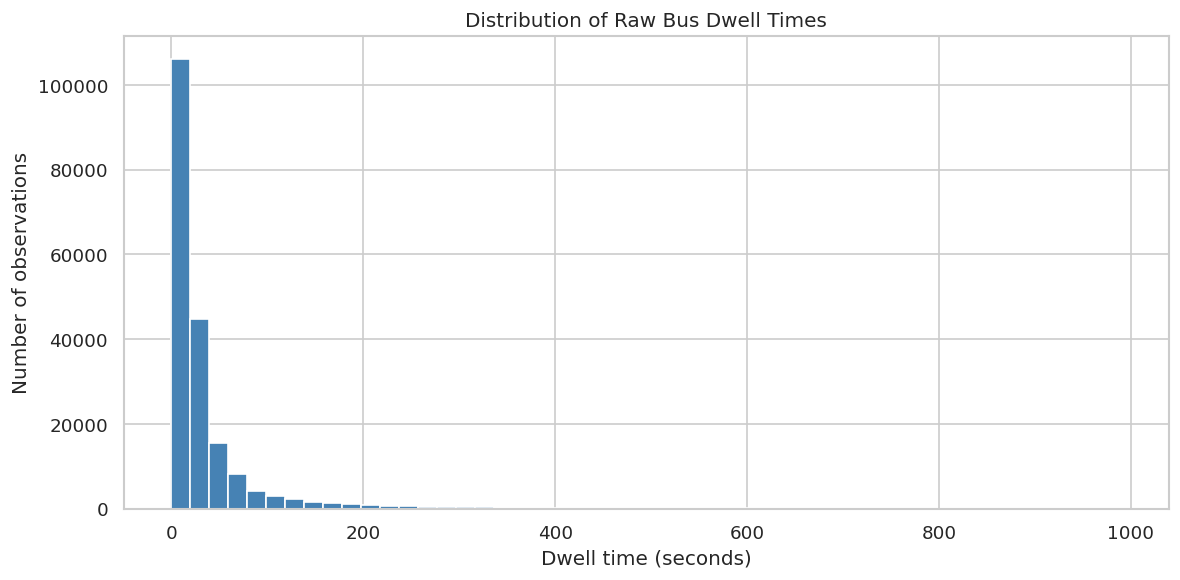

In [14]:
# Visualise the original dwell-time distribution

plt.figure(figsize=(10, 5))

plt.hist(
    dwell_df["dwell_time_in_seconds"].dropna(),
    bins=50,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Raw Bus Dwell Times")
plt.xlabel("Dwell time (seconds)")
plt.ylabel("Number of observations")

plt.tight_layout()

# Save figure for the report
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

plt.savefig(
    FIGURE_DIR / "01_raw_dwell_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 1.7 Data preprocessing and observation selection

The raw dataset contains 191,602 GPS-derived bus-stop observations across 27 bus stops and two travel directions.

Initial inspection identified no missing values, exact duplicate rows or negative dwell times. However, 44,512 observations recorded zero dwell time.

Zero-duration observations are retained for data-quality assessment but excluded from the primary positive-duration boarding-service model. Their potential influence is considered separately.

The analysis focuses on non-terminal bus stops and weekday morning peak hours between 07:00 and 09:00.

Travel directions are analysed separately to avoid combining potentially independent boarding facilities.

The reference bus stop is selected objectively using the highest number of recorded positive-dwell arrivals during the predefined observation window.

The resulting estimates represent observed Route 654 operations rather than the total demand from all bus routes at a Colombo bus halt.


In [ ]:
# Create a working copy to preserve the original dataset

df = dwell_df.copy()

# Convert observation dates
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Combine date and arrival time
df["arrival_datetime"] = pd.to_datetime(
    df["date"].dt.strftime("%Y-%m-%d")
    + " "
    + df["arrival_time"].astype(str),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Combine date and departure time
df["departure_datetime"] = pd.to_datetime(
    df["date"].dt.strftime("%Y-%m-%d")
    + " "
    + df["departure_time"].astype(str),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Handle departures occurring after midnight
overnight = (
    df["departure_datetime"] < df["arrival_datetime"]
)

df.loc[overnight, "departure_datetime"] += (
    pd.Timedelta(days=1)
)

# Check timestamp conversion
print("TIMESTAMP CONVERSION")
print("-" * 45)

print("Invalid dates:",
      df["date"].isna().sum())

print("Invalid arrival timestamps:",
      df["arrival_datetime"].isna().sum())

print("Invalid departure timestamps:",
      df["departure_datetime"].isna().sum())

print("Overnight records:", overnight.sum())

print("First observation:", df["date"].min())
print("Last observation:", df["date"].max())

In [16]:
# Validate timestamps and recorded dwell durations

df["calculated_dwell"] = (
    df["departure_datetime"]
    - df["arrival_datetime"]
).dt.total_seconds()

df["dwell_difference"] = abs(
    df["calculated_dwell"]
    - df["dwell_time_in_seconds"]
)

print("DWELL TIME VALIDATION")
print("-" * 45)

print("Records differing by more than 1 second:",
      (df["dwell_difference"] > 1).sum())

# Remove invalid observations

clean_df = df.dropna(
    subset=[
        "date",
        "arrival_datetime",
        "departure_datetime",
        "dwell_time_in_seconds"
    ]
).copy()

clean_df = clean_df[
    (clean_df["dwell_time_in_seconds"] >= 0)
    & (clean_df["calculated_dwell"] >= 0)
    & (clean_df["dwell_difference"] <= 1)
].copy()

print("\nOriginal records:", len(df))
print("Valid records:", len(clean_df))
print("Removed records:", len(df) - len(clean_df))

print("Data retained (%):",
      round(len(clean_df) / len(df) * 100, 2))

DWELL TIME VALIDATION
---------------------------------------------
Records differing by more than 1 second: 0

Original records: 191602
Valid records: 191602
Removed records: 0
Data retained (%): 100.0


In [ ]:
# Prepare bus stop metadata

stop_metadata = stops_df.copy()

# Identify numeric stop IDs, excluding terminals
numeric_ids = pd.to_numeric(
    stop_metadata["stop_id"],
    errors="coerce"
)

stop_metadata = stop_metadata[
    numeric_ids.notna()
].copy()

stop_metadata["bus_stop"] = (
    stop_metadata["stop_id"].astype(int)
)

stop_metadata = stop_metadata.drop_duplicates(
    subset=["bus_stop"]
)

# Keep only eligible non-terminal bus stops

eligible_df = clean_df[
    clean_df["bus_stop"].isin(
        stop_metadata["bus_stop"]
    )
].copy()

print("BUS STOP SELECTION")
print("-" * 45)

print("Eligible bus stops:",
      eligible_df["bus_stop"].nunique())

print("Eligible observations:",
      len(eligible_df))

In [18]:
# Define the primary observation window

PEAK_START = 7
PEAK_END = 9
WINDOW_HOURS = PEAK_END - PEAK_START

# Extract weekday and hour

eligible_df["weekday"] = (
    eligible_df["arrival_datetime"].dt.dayofweek
)

eligible_df["hour"] = (
    eligible_df["arrival_datetime"].dt.hour
)

# Monday-Friday, 07:00-09:00

peak_df = eligible_df[
    (eligible_df["weekday"] < 5)
    & (eligible_df["hour"] >= PEAK_START)
    & (eligible_df["hour"] < PEAK_END)
].copy()

# Separate positive-duration service observations

service_peak_df = peak_df[
    peak_df["dwell_time_in_seconds"] > 0
].copy()

print("PEAK-HOUR OBSERVATIONS")
print("-" * 45)

print("Observation window: 07:00-09:00")
print("Days: Monday-Friday")

print("All peak-hour records:", len(peak_df))

print("Positive dwell records:",
      len(service_peak_df))

print("Zero dwell records:",
      len(peak_df) - len(service_peak_df))

print("Observed weekdays:",
      peak_df["date"].nunique())

PEAK-HOUR OBSERVATIONS
---------------------------------------------
Observation window: 07:00-09:00
Days: Monday-Friday
All peak-hour records: 21697
Positive dwell records: 17098
Zero dwell records: 4599
Observed weekdays: 193


In [19]:
# Rank bus stops using positive-dwell peak-hour records

stop_ranking = (
    service_peak_df
    .groupby(["bus_stop", "direction"])
    .agg(
        arrivals=("trip_id", "size"),
        observed_days=("date", "nunique"),
        mean_dwell_seconds=(
            "dwell_time_in_seconds", "mean"
        ),
        median_dwell_seconds=(
            "dwell_time_in_seconds", "median"
        )
    )
    .reset_index()
)

# Add bus stop names

stop_ranking = stop_ranking.merge(
    stop_metadata[["bus_stop", "address"]],
    on="bus_stop",
    how="left"
)

stop_ranking = stop_ranking.sort_values(
    ["arrivals", "bus_stop", "direction"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("TOP 10 REFERENCE BUS STOP CANDIDATES")
print("-" * 60)

print(
    stop_ranking.head(10)
    .round(2)
    .to_string(index=False)
)

# Select the highest-ranked stop

selected_stop = stop_ranking.iloc[0]

STOP_ID = int(selected_stop["bus_stop"])
DIRECTION = int(selected_stop["direction"])
STOP_NAME = selected_stop["address"]

print("\nSELECTED REFERENCE BUS STOP")
print("-" * 45)

print("Stop ID:", STOP_ID)
print("Stop name:", STOP_NAME)
print("Direction:", DIRECTION)
print("Positive-dwell arrivals:",
      selected_stop["arrivals"])
print("Observed days:",
      selected_stop["observed_days"])

TOP 10 REFERENCE BUS STOP CANDIDATES
------------------------------------------------------------
 bus_stop  direction  arrivals  observed_days  mean_dwell_seconds  median_dwell_seconds                        address
      109          1       842            184               55.99                  44.0                     Warapitiya
      105          1       841            184              119.53                  94.0            Tennekumbura Bridge
      110          1       835            183               30.89                  28.0 Pallekele (Provincial Council)
      113          1       776            185               27.49                  17.0                            BOI
      106          1       767            184               26.18                  23.0      Kalapura Junction Busstop
      101          1       733            181               61.13                  49.0                     Wales Park
      206          2       724            188               66.11    

In [20]:
# Extract observations for the selected reference stop

selected_all = peak_df[
    (peak_df["bus_stop"] == STOP_ID)
    & (peak_df["direction"] == DIRECTION)
].copy()

selected_df = selected_all[
    selected_all["dwell_time_in_seconds"] > 0
].copy()

selected_df = selected_df.sort_values(
    "arrival_datetime"
)

# Identify route-active observation days

active_days = pd.DatetimeIndex(
    peak_df["date"].unique()
).sort_values()

# Count daily positive-dwell arrivals
# Include zero counts on route-active days

daily_arrivals = (
    selected_df.groupby("date")
    .size()
    .reindex(active_days, fill_value=0)
)

daily_rates = daily_arrivals / WINDOW_HOURS

# Preliminary arrival rate

lambda_observed = daily_rates.mean()

# Preliminary service rate

mean_service_seconds = (
    selected_df["dwell_time_in_seconds"].mean()
)

mu_observed = 3600 / mean_service_seconds

# Single-bay utilisation

rho_observed = lambda_observed / mu_observed

print("PRELIMINARY SIMULATION PARAMETERS")
print("=" * 50)

print("Reference stop:", STOP_NAME)
print("Stop ID:", STOP_ID)

print("Route-active weekdays:", len(active_days))

print("Positive-dwell arrivals:", len(selected_df))

print("All recorded arrivals:", len(selected_all))

print(f"Arrival rate: {lambda_observed:.4f} buses/hour")

print(f"Mean service time: {mean_service_seconds:.4f} seconds")

print(f"Service rate: {mu_observed:.4f} buses/hour/bay")

print(f"Single-bay utilisation: {rho_observed:.4f}")

print(f"Utilisation percentage: {rho_observed * 100:.2f}%")

print("\nDaily arrival-rate statistics:")

print(daily_rates.describe().round(4).to_string())

PRELIMINARY SIMULATION PARAMETERS
Reference stop: Warapitiya
Stop ID: 109
Route-active weekdays: 193
Positive-dwell arrivals: 842
All recorded arrivals: 881
Arrival rate: 2.1813 buses/hour
Mean service time: 55.9869 seconds
Service rate: 64.3007 buses/hour/bay
Single-bay utilisation: 0.0339
Utilisation percentage: 3.39%

Daily arrival-rate statistics:
count    193.0000
mean       2.1813
std        1.1184
min        0.0000
25%        1.5000
50%        2.5000
75%        3.0000
max        4.5000


### 1.8 Statistical input modelling and uncertainty analysis

Warapitiya (Stop ID 109, Direction 1) was selected as the empirical reference stop because it contained the highest number of recorded positive-dwell arrivals during the predefined weekday morning observation window.

A total of 842 positive-dwell observations were identified across 193 route-active weekdays. Positive-dwell arrivals were recorded at the selected stop on 184 of these days.

The preliminary observed arrival rate was 2.1813 buses per hour, while the mean positive dwell time was 55.9869 seconds.

The corresponding estimated service rate was 64.3007 buses per hour per boarding bay.

The estimated single-bay utilisation was approximately 3.39%, indicating that the observed single-route demand is substantially below the theoretical service capacity.

Therefore, the empirical observations are used as a baseline for input calibration, while explicitly hypothetical demand scenarios are introduced to investigate higher-demand urban bus-halt conditions.

Statistical analysis is performed to quantify parameter uncertainty, investigate interarrival and service-time distributions, and evaluate the assumptions of the M/M/c queueing model.

In [21]:
# Estimate uncertainty in the input parameters

CONFIDENCE_LEVEL = 0.95

def mean_confidence_interval(values, confidence=0.95):
    values = np.asarray(values, dtype=float)

    n = len(values)
    mean = np.mean(values)
    standard_error = stats.sem(values)

    margin = stats.t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    ) * standard_error

    return mean, mean - margin, mean + margin


# Arrival-rate confidence interval

lambda_mean, lambda_lower, lambda_upper = (
    mean_confidence_interval(daily_rates)
)

# Service-time confidence interval
# Bootstrap whole observed days to preserve within-day grouping

service_by_day = (
    selected_df.groupby("date")["dwell_time_in_seconds"]
    .agg(["sum", "count"])
)

bootstrap_rng = np.random.default_rng(SEED)

bootstrap_indices = bootstrap_rng.integers(
    0,
    len(service_by_day),
    size=(5000, len(service_by_day))
)

bootstrap_means = (
    service_by_day["sum"].to_numpy()[bootstrap_indices].sum(axis=1)
    / service_by_day["count"].to_numpy()[bootstrap_indices].sum(axis=1)
)

service_mean = selected_df["dwell_time_in_seconds"].mean()

service_lower, service_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

# Convert service-time interval into service-rate interval

mu_lower = 3600 / service_upper
mu_upper = 3600 / service_lower

print("95% CONFIDENCE INTERVALS")
print("=" * 50)

print(f"Arrival rate: {lambda_mean:.4f} buses/hour")
print(f"95% CI: [{lambda_lower:.4f}, {lambda_upper:.4f}]")

print(f"\nMean service time: {service_mean:.4f} seconds")
print(f"95% CI: [{service_lower:.4f}, {service_upper:.4f}]")

print(f"\nService rate: {mu_observed:.4f} buses/hour/bay")
print(f"95% CI: [{mu_lower:.4f}, {mu_upper:.4f}]")

95% CONFIDENCE INTERVALS
Arrival rate: 2.1813 buses/hour
95% CI: [2.0226, 2.3401]

Mean service time: 55.9869 seconds
95% CI: [51.8258, 60.5328]

Service rate: 64.3007 buses/hour/bay
95% CI: [59.4719, 69.4635]


In [22]:
# Calculate interarrival times within each observation day

selected_df = selected_df.sort_values(
    ["date", "arrival_datetime"]
).copy()

selected_df["interarrival_seconds"] = (
    selected_df.groupby("date")["arrival_datetime"]
    .diff()
    .dt.total_seconds()
)

raw_interarrival = (
    selected_df["interarrival_seconds"].dropna()
)

interarrival = raw_interarrival[
    raw_interarrival > 0
].copy()

interarrival_mean = interarrival.mean()
interarrival_std = interarrival.std()

interarrival_cv = (
    interarrival_std / interarrival_mean
)

print("INTERARRIVAL TIME ANALYSIS")
print("=" * 50)

print("Valid positive intervals:", len(interarrival))

print("Zero-second intervals:",
      (raw_interarrival == 0).sum())

print(f"Mean: {interarrival_mean:.2f} seconds")

print(f"Mean: {interarrival_mean / 60:.2f} minutes")

print(f"Standard deviation: {interarrival_std:.2f} seconds")

print(f"Coefficient of variation: {interarrival_cv:.4f}")

print("\nDescriptive statistics:")

print(interarrival.describe().round(4).to_string())

INTERARRIVAL TIME ANALYSIS
Valid positive intervals: 656
Zero-second intervals: 2
Mean: 1129.91 seconds
Mean: 18.83 minutes
Standard deviation: 813.51 seconds
Coefficient of variation: 0.7200

Descriptive statistics:
count     656.0000
mean     1129.9070
std       813.5075
min        13.0000
25%       581.7500
50%       880.5000
75%      1412.2500
max      5559.0000


In [23]:
# Analyse positive dwell-time observations

service_times = (
    selected_df["dwell_time_in_seconds"]
    .to_numpy(dtype=float)
)

service_std = np.std(service_times, ddof=1)

service_cv = (
    service_std / np.mean(service_times)
)

# Investigate the upper tail

p95 = np.percentile(service_times, 95)
p99 = np.percentile(service_times, 99)

trimmed_service_times = service_times[
    service_times <= p99
]

print("SERVICE TIME ANALYSIS")
print("=" * 50)

print("Observations:", len(service_times))

print(f"Mean: {np.mean(service_times):.4f} seconds")

print(f"Median: {np.median(service_times):.4f} seconds")

print(f"Standard deviation: {service_std:.4f} seconds")

print(f"Coefficient of variation: {service_cv:.4f}")

print(f"95th percentile: {p95:.2f} seconds")

print(f"99th percentile: {p99:.2f} seconds")

print(f"Maximum: {np.max(service_times):.2f} seconds")

print("\nOUTLIER SENSITIVITY")

print("Observations above 99th percentile:",
      len(service_times) - len(trimmed_service_times))

print(f"Original mean: {np.mean(service_times):.4f}")

print(f"Trimmed mean: {np.mean(trimmed_service_times):.4f}")

print(f"Original service rate: {3600 / np.mean(service_times):.4f}")

print(f"Trimmed service rate: {3600 / np.mean(trimmed_service_times):.4f}")

SERVICE TIME ANALYSIS
Observations: 842
Mean: 55.9869 seconds
Median: 44.0000 seconds
Standard deviation: 49.4816 seconds
Coefficient of variation: 0.8838
95th percentile: 151.95 seconds
99th percentile: 242.00 seconds
Maximum: 515.00 seconds

OUTLIER SENSITIVITY
Observations above 99th percentile: 8
Original mean: 55.9869
Trimmed mean: 53.5827
Original service rate: 64.3007
Trimmed service rate: 67.1858


In [24]:
# Fit candidate service-time distributions

distributions = {
    "Exponential": stats.expon,
    "Gamma": stats.gamma,
    "Lognormal": stats.lognorm
}

fit_results = []
fitted_parameters = {}

for name, distribution in distributions.items():

    # Fix location at zero for positive service times
    parameters = distribution.fit(
        service_times,
        floc=0
    )

    fitted_parameters[name] = parameters

    log_likelihood = np.sum(
        distribution.logpdf(
            service_times,
            *parameters
        )
    )

    # Location is fixed, so exclude it
    k = len(parameters) - 1

    aic = 2 * k - 2 * log_likelihood

    bic = (
        k * np.log(len(service_times))
        - 2 * log_likelihood
    )

    ks_statistic = stats.kstest(
        service_times,
        distribution.cdf,
        args=parameters
    ).statistic

    fit_results.append({
        "Distribution": name,
        "AIC": aic,
        "BIC": bic,
        "KS_statistic": ks_statistic
    })

fit_df = pd.DataFrame(fit_results)

fit_df = fit_df.sort_values(
    "AIC"
).reset_index(drop=True)

fit_df["Delta_AIC"] = (
    fit_df["AIC"] - fit_df["AIC"].min()
)

print("SERVICE TIME DISTRIBUTION COMPARISON")
print("=" * 60)

print(fit_df.round(4).to_string(index=False))

print("\nBest distribution according to AIC:",
      fit_df.iloc[0]["Distribution"])

print("\nFitted parameters:")

for name, parameters in fitted_parameters.items():
    print(name, ":", parameters)

SERVICE TIME DISTRIBUTION COMPARISON
Distribution       AIC       BIC  KS_statistic  Delta_AIC
   Lognormal 8233.5001 8242.9717        0.1394     0.0000
       Gamma 8320.9950 8330.4665        0.1162    87.4948
 Exponential 8464.2993 8469.0351        0.2243   230.7992

Best distribution according to AIC: Lognormal

Fitted parameters:
Exponential : (0.0, 55.98693586698337)
Gamma : (1.7960139774282688, 0, np.float64(31.172884270729146))
Lognormal : (np.float64(0.7759553844290873), 0, np.float64(41.33039937132917))


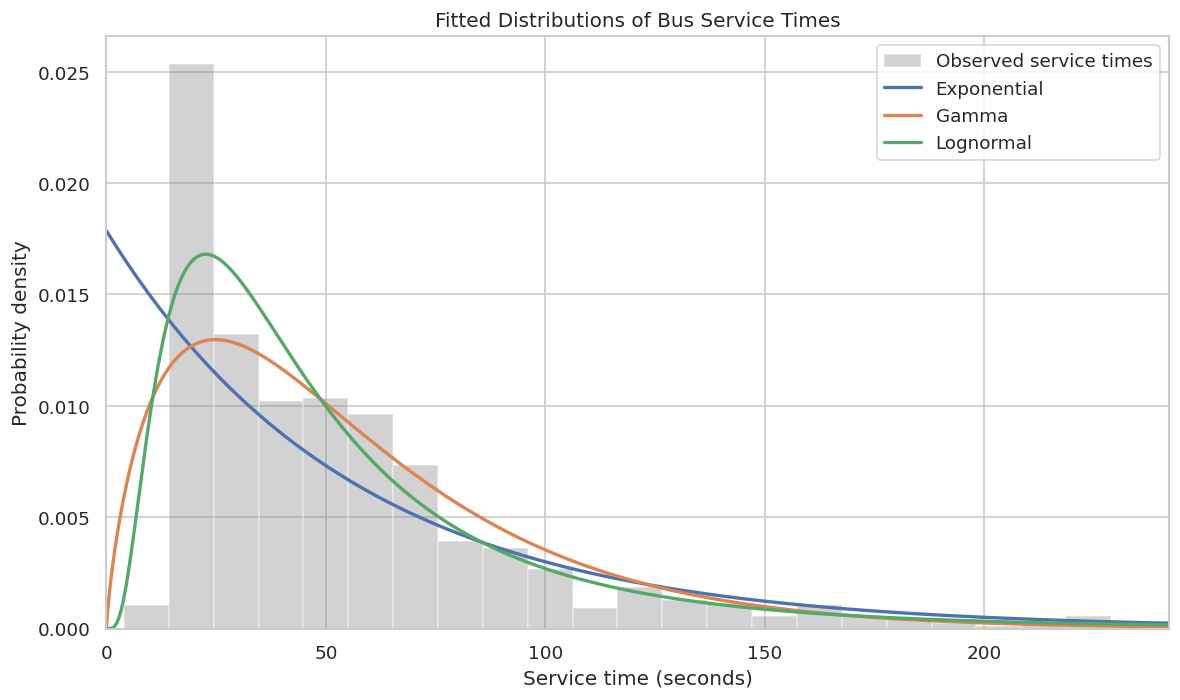

In [25]:
# Visualise fitted service-time distributions

x = np.linspace(
    0.01,
    np.percentile(service_times, 99),
    500
)

plt.figure(figsize=(10, 6))

plt.hist(
    service_times,
    bins=50,
    density=True,
    alpha=0.35,
    color="grey",
    label="Observed service times"
)

for name, distribution in distributions.items():

    parameters = fitted_parameters[name]

    plt.plot(
        x,
        distribution.pdf(x, *parameters),
        linewidth=2,
        label=name
    )

plt.title("Fitted Distributions of Bus Service Times")
plt.xlabel("Service time (seconds)")
plt.ylabel("Probability density")

plt.xlim(0, np.percentile(service_times, 99))

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_service_distribution_fits.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

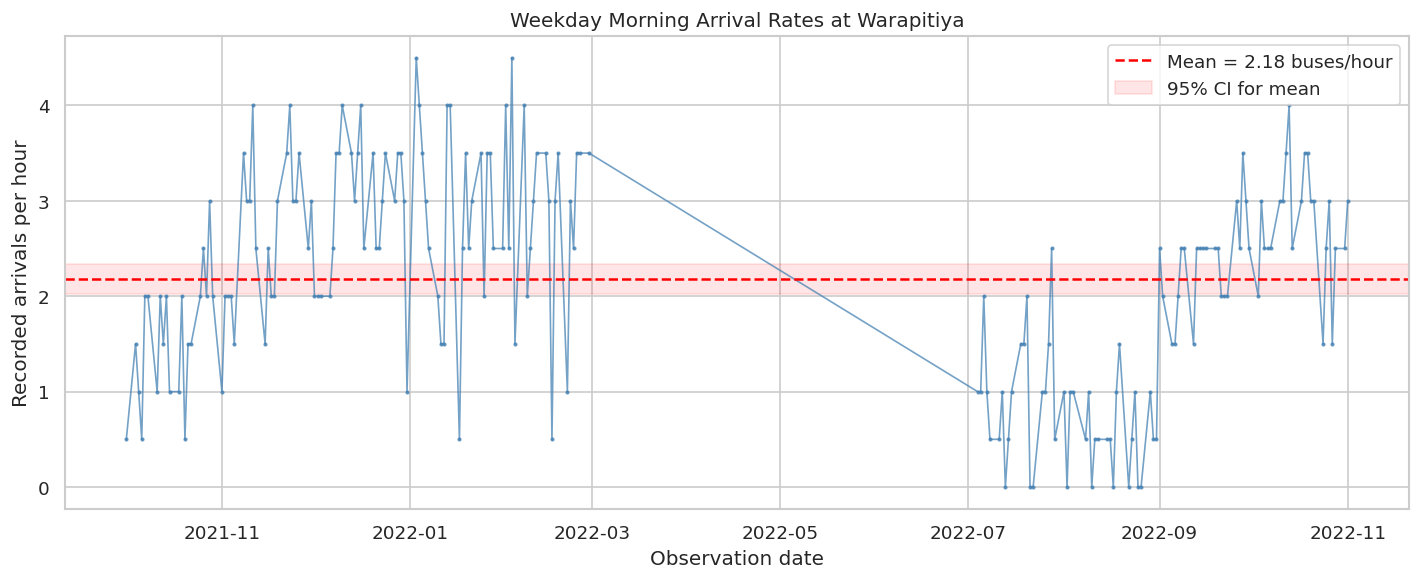

In [26]:
# Visualise daily observed arrival rates

plt.figure(figsize=(12, 5))

plt.plot(
    daily_rates.index,
    daily_rates.values,
    color="steelblue",
    alpha=0.75,
    linewidth=1,
    marker=".",
    markersize=3
)

plt.axhline(
    lambda_observed,
    color="red",
    linestyle="--",
    label=f"Mean = {lambda_observed:.2f} buses/hour"
)

plt.axhspan(
    lambda_lower,
    lambda_upper,
    color="red",
    alpha=0.1,
    label="95% CI for mean"
)

plt.title("Weekday Morning Arrival Rates at Warapitiya")
plt.xlabel("Observation date")
plt.ylabel("Recorded arrivals per hour")

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "03_daily_arrival_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Examine the variability of daily arrival counts

count_mean = daily_arrivals.mean()
count_variance = daily_arrivals.var(ddof=1)

dispersion_index = count_variance / count_mean

print("ARRIVAL PROCESS DIAGNOSTICS")
print("=" * 50)

print(f"Mean daily peak-window count: {count_mean:.4f}")

print(f"Variance of daily counts: {count_variance:.4f}")

print(f"Dispersion index: {dispersion_index:.4f}")

print(f"Interarrival CV: {interarrival_cv:.4f}")

print(f"Service-time CV: {service_cv:.4f}")

print("\nInterpretation:")

if dispersion_index > 1.2:
    print("Daily counts show overdispersion relative to Poisson.")

elif dispersion_index < 0.8:
    print("Daily counts show underdispersion relative to Poisson.")

else:
    print("Daily count dispersion is approximately Poisson-like.")

ARRIVAL PROCESS DIAGNOSTICS
Mean daily peak-window count: 4.3627
Variance of daily counts: 5.0032
Dispersion index: 1.1468
Interarrival CV: 0.7200
Service-time CV: 0.8838

Interpretation:
Daily count dispersion is approximately Poisson-like.


## 2. Model, assumptions and equations

### 2.1 Conceptual model

The bus halt is represented as a multi-server queueing system in which buses arrive, wait when all boarding bays are occupied, receive service at an available boarding bay and depart after service completion.

The primary mathematical model is an M/M/c queue, where:

- The first M represents a Poisson arrival process with exponentially distributed interarrival times.
- The second M represents exponentially distributed service times.
- c represents the number of parallel boarding bays.

Each bus is treated as an individual entity, and each boarding bay is treated as a service resource.

The model investigates configurations containing one, two and three boarding bays.

### 2.2 Model assumptions

1. Bus arrivals follow a homogeneous Poisson process within each experimental scenario.
2. Service times follow an exponential distribution in the primary model.
3. Arrival and service processes are independent.
4. Boarding bays are identical and operate independently.
5. Buses are served according to the First-Come, First-Served (FCFS) discipline.
6. Each boarding bay accommodates one bus at a time.
7. Queue capacity is assumed to be unlimited.
8. Buses do not abandon the queue or refuse to join it.
9. Arrival and service rates remain constant within each simulation scenario.
10. GPS-derived positive dwell times are used as approximate service-time measurements.
11. Boarding-bay interference, overtaking restrictions and downstream traffic blocking are not explicitly modelled.
12. Higher-demand scenarios are hypothetical stress tests rather than measured Colombo traffic conditions.

### 2.3 Empirical parameter calibration

The primary model is calibrated using 842 positive-dwell observations recorded at Warapitiya (Stop ID 109, Direction 1) across 193 route-active weekdays between 07:00 and 09:00.

| Parameter | Symbol | Estimated value |
|---|---|---|
| Arrival rate | $\lambda$ | 2.1813 buses/hour |
| Mean service time | $E[S]$ | 55.9869 seconds |
| Service rate per bay | $\mu$ | 64.3007 buses/hour |
| Number of boarding bays | $c$ | 1, 2, 3 |
| Queue discipline | FCFS | First-Come, First-Served |
| Confidence level | $1-\alpha$ | 95% |

The original positive dwell-time observations are retained for the primary analysis. For comparison, a trimmed input estimate excludes observations above the 99th percentile. The simulation experiments use the original estimate.

### 2.4 Justification of distribution assumptions

The observed daily arrival-count dispersion index is 1.1468, indicating approximately Poisson-like count variability.

The observed interarrival-time coefficient of variation is 0.7200, while the service-time coefficient of variation is 0.8838. These results indicate that the exponential assumptions are approximations rather than exact descriptions of the empirical processes.

The lognormal distribution provides the lowest AIC and BIC among the fitted service-time distributions, while the gamma distribution provides the lowest descriptive KS statistic.

The M/M/c model is retained as an analytically tractable baseline. An M/G/c extension using lognormal service times is used to investigate sensitivity to the service-time distribution assumption.

### 2.5 Mathematical formulation

#### Arrival rate

The observed arrival rate is estimated as:

$$
\lambda = \frac{N}{D H}
$$

where $N$ is the number of positive-dwell arrivals, $D$ is the number of route-active weekdays and $H$ is the observation duration in hours.

#### Service rate

The service rate per boarding bay is:

$$
\mu = \frac{3600}{\bar{s}}
$$

where $\bar{s}$ is the mean service time in seconds.

#### Offered traffic load

$$
a = \frac{\lambda}{\mu}
$$

#### Boarding-bay utilisation

$$
\rho = \frac{\lambda}{c\mu}
$$

A stationary M/M/c queue exists only when:

$$
\rho < 1
$$

When $\rho \geq 1$, the system does not have a finite steady-state queue length or waiting time.

#### Probability of an empty system

For a stable M/M/c queue [2]:

$$
P_0 =
\left[
\sum_{n=0}^{c-1}\frac{a^n}{n!}
+
\frac{a^c}{c!(1-\rho)}
\right]^{-1}
$$

#### Probability of waiting (Erlang C)

$$
P_{\mathrm{wait}} =
\frac{a^c}{c!(1-\rho)}P_0
$$

#### Expected queue waiting time

$$
W_q = \frac{P_{\mathrm{wait}}}{c\mu-\lambda}
$$

#### Expected queue length

Using Little's Law:

$$
L_q = \lambda W_q
$$

#### Expected total time in the system

$$
W = W_q + \frac{1}{\mu}
$$

#### Expected number of buses in the system

$$
L = \lambda W
$$

All analytical time calculations are initially expressed in hours and converted to seconds or minutes for reporting.

These equations provide theoretical reference values against which the discrete-event simulation results can be verified.

In [28]:
# Final model parameters

LAMBDA_BASE = float(lambda_observed)
MU_BASE = float(mu_observed)

MEAN_SERVICE_SECONDS = float(
    np.mean(service_times)
)

MU_TRIMMED = float(
    3600 / np.mean(trimmed_service_times)
)

BAY_CONFIGURATIONS = [1, 2, 3]

DEMAND_MULTIPLIERS = [1, 4, 10, 20, 28, 35]

print("FINAL MODEL PARAMETERS")
print("=" * 50)

print(f"Arrival rate: {LAMBDA_BASE:.4f} buses/hour")

print(f"Service rate: {MU_BASE:.4f} buses/hour/bay")

print(f"Mean service time: {MEAN_SERVICE_SECONDS:.4f} seconds")

print(f"Trimmed service rate: {MU_TRIMMED:.4f}")

print("Boarding-bay configurations:", BAY_CONFIGURATIONS)

print("Demand multipliers:", DEMAND_MULTIPLIERS)

FINAL MODEL PARAMETERS
Arrival rate: 2.1813 buses/hour
Service rate: 64.3007 buses/hour/bay
Mean service time: 55.9869 seconds
Trimmed service rate: 67.1858
Boarding-bay configurations: [1, 2, 3]
Demand multipliers: [1, 4, 10, 20, 28, 35]


In [29]:
# Analytical M/M/c queueing model

def mmc_analytical(arrival_rate, service_rate, servers):

    if arrival_rate < 0 or service_rate <= 0:
        raise ValueError("Invalid arrival or service rate.")

    if not isinstance(servers, (int, np.integer)) or servers < 1:
        raise ValueError("Servers must be a positive integer.")

    # Offered load and utilisation
    a = arrival_rate / service_rate
    rho = arrival_rate / (servers * service_rate)

    # Check steady-state stability
    if rho >= 1:

        return {
            "stable": False,
            "rho": rho,
            "P0": np.nan,
            "P_wait": np.nan,
            "Wq_seconds": np.inf,
            "W_seconds": np.inf,
            "Lq": np.inf,
            "L": np.inf
        }

    # Probability of an empty system
    summation = sum(
        a**n / math.factorial(n)
        for n in range(servers)
    )

    final_term = (
        a**servers
        / (
            math.factorial(servers)
            * (1 - rho)
        )
    )

    P0 = 1 / (summation + final_term)

    # Erlang C probability of waiting
    P_wait = final_term * P0

    # Expected waiting time in hours
    Wq = P_wait / (
        servers * service_rate - arrival_rate
    )

    # Total time in system in hours
    W = Wq + 1 / service_rate

    # Little's Law
    Lq = arrival_rate * Wq
    L = arrival_rate * W

    return {
        "stable": True,
        "rho": rho,
        "P0": P0,
        "P_wait": P_wait,
        "Wq_seconds": Wq * 3600,
        "W_seconds": W * 3600,
        "Lq": Lq,
        "L": L
    }


print("Analytical M/M/c model implemented successfully.")

Analytical M/M/c model implemented successfully.


## 3. Discrete-event simulation implementation

### 3.1 Simulation approach

A discrete-event simulation is implemented using the SimPy Python library [3] to represent bus arrivals, queue formation, boarding-bay allocation, service completion and departures.

Each bus is represented as an individual process, while the boarding bays are represented using a shared resource with configurable capacity.

The simulation uses seconds as its internal time unit.

Interarrival times are generated from an exponential distribution based on the calibrated arrival rate. The primary model uses exponentially distributed service times, while the extended model supports lognormal service times.

A First-Come, First-Served queue discipline is implemented through the SimPy resource allocation mechanism.

Independent random number streams are used for arrival and service processes to support reproducibility.

A warm-up period is excluded from performance measurements to reduce initialisation bias during steady-state experiments.

The simulation records queue waiting time, service time, total system time, queue length, probability of waiting and boarding-bay utilisation.

For long replication sweeps, the same FCFS model can be evaluated directly. In arrival order, a bus starts service at the later of its arrival and the earliest time a bay is available. A min-heap tracks the next available bay. NumPy generates inputs from the same two seeded random streams and summarizes the event times without SimPy process objects or a per-bus DataFrame.

Queue length is integrated from queued arrivals to service starts. Bay occupancy is integrated from service starts to departures. Both are measured over the same window as the SimPy model, and buses arriving before the cutoff can finish service afterward. The detailed SimPy implementation remains the reference for the per-bus checks and for simultaneous events that require its tie-breaking rules. The optimized sweeps execute every replication from its seed.

In [33]:
def simulate_bus_halt(
    arrival_rate,
    service_rate,
    bays=1,
    simulation_hours=100,
    warmup_hours=10,
    seed=42,
    service_distribution="exponential",
    lognormal_sigma=0.7759553844290873
):

    # Validate input parameters
    if arrival_rate <= 0 or service_rate <= 0:
        raise ValueError("Rates must be positive.")

    if not isinstance(bays, (int, np.integer)) or bays < 1:
        raise ValueError("Bays must be a positive integer.")

    if simulation_hours <= warmup_hours or warmup_hours < 0:
        raise ValueError("Invalid simulation duration.")

    if service_distribution not in ["exponential", "lognormal"]:
        raise ValueError("Unsupported service distribution.")

    # Convert hours to seconds
    end_time = simulation_hours * 3600
    warmup_time = warmup_hours * 3600
    observation_time = end_time - warmup_time

    mean_interarrival = 3600 / arrival_rate
    mean_service = 3600 / service_rate

    # Independent random number streams
    seed_sequence = np.random.SeedSequence(seed)
    arrival_seed, service_seed = seed_sequence.spawn(2)

    arrival_rng = np.random.default_rng(arrival_seed)
    service_rng = np.random.default_rng(service_seed)

    # Create simulation environment
    env = simpy.Environment()

    # Boarding bays
    resource = simpy.Resource(env, capacity=bays)

    # Store individual bus records
    records = []

    # State variables for time-weighted statistics
    state = {
        "last_time": 0.0,
        "queue": 0,
        "busy": 0,
        "queue_area": 0.0,
        "busy_area": 0.0,
        "max_queue": 0
    }

    def update_state():

        now = env.now

        start = max(
            state["last_time"],
            warmup_time
        )

        finish = min(now, end_time)

        duration = max(0, finish - start)

        state["queue_area"] += (
            state["queue"] * duration
        )

        state["busy_area"] += (
            state["busy"] * duration
        )

        state["last_time"] = now

    def generate_service_time():

        if service_distribution == "exponential":

            return service_rng.exponential(
                mean_service
            )

        # Mean-matched lognormal distribution
        log_mean = (
            np.log(mean_service)
            - lognormal_sigma**2 / 2
        )

        return service_rng.lognormal(
            mean=log_mean,
            sigma=lognormal_sigma
        )

    def bus_process(bus_id, service_time):

        arrival_time = env.now

        # Request a boarding bay
        with resource.request() as request:

            queued = not request.triggered

            if queued:
                update_state()
                state["queue"] += 1

                if warmup_time <= env.now < end_time:
                    state["max_queue"] = max(
                        state["max_queue"],
                        state["queue"]
                    )

            yield request

            # Service begins
            update_state()

            if queued:
                state["queue"] -= 1

            state["busy"] += 1

            service_start = env.now

            waiting_time = (
                service_start - arrival_time
            )

            # Complete service
            yield env.timeout(service_time)

            departure_time = env.now

            update_state()
            state["busy"] -= 1

            # Record buses arriving in measurement window
            if warmup_time <= arrival_time < end_time:

                records.append({
                    "bus_id": bus_id,
                    "arrival_time": arrival_time,
                    "service_start": service_start,
                    "departure_time": departure_time,
                    "waiting_time": waiting_time,
                    "service_time": service_time,
                    "system_time": (
                        departure_time - arrival_time
                    )
                })

    def arrival_generator():

        bus_id = 0

        while True:

            interarrival_time = arrival_rng.exponential(
                mean_interarrival
            )

            if env.now + interarrival_time >= end_time:
                break

            yield env.timeout(interarrival_time)

            bus_id += 1

            service_time = generate_service_time()

            env.process(
                bus_process(bus_id, service_time)
            )

    # Start bus arrivals
    env.process(arrival_generator())

    # Run until the observation period ends
    env.run(until=end_time)

    # Finalise time-weighted statistics
    update_state()

    queue_at_end = state["queue"]

    busy_at_end = state["busy"]

    # Complete remaining buses without generating new arrivals
    env.run()

    # Convert individual bus records into a DataFrame
    bus_df = pd.DataFrame(records)

    if bus_df.empty:
        raise RuntimeError("No buses recorded.")

    # Performance measures
    metrics = {
        "arrival_rate": arrival_rate,
        "service_rate": service_rate,
        "bays": bays,
        "seed": seed,
        "distribution": service_distribution,
        "simulation_hours": simulation_hours,
        "warmup_hours": warmup_hours,
        "buses_recorded": len(bus_df),

        "observed_arrival_rate": (
            len(bus_df) / (observation_time / 3600)
        ),

        "mean_wait_seconds": (
            bus_df["waiting_time"].mean()
        ),

        "mean_service_seconds": (
            bus_df["service_time"].mean()
        ),

        "mean_system_seconds": (
            bus_df["system_time"].mean()
        ),

        "p95_wait_seconds": (
            bus_df["waiting_time"].quantile(0.95)
        ),

        "probability_wait": (
            bus_df["waiting_time"] > 0
        ).mean(),

        "mean_queue_length": (
            state["queue_area"] / observation_time
        ),

        "utilisation": (
            state["busy_area"]
            / (bays * observation_time)
        ),

        "max_queue_length": state["max_queue"],

        "queue_at_end": queue_at_end,

        "busy_at_end": busy_at_end,

        "theoretical_stable": (
            arrival_rate / (bays * service_rate) < 1
        )
    }

    return metrics, bus_df


print("Discrete-event simulation implemented successfully.")

Discrete-event simulation implemented successfully.


In [ ]:
from heapq import heapreplace


def fcfs_event_times(arrival_rng, service_rng, mean_interarrival, draw_service, end_time, bays):
    """Generate the same arrival and service draws in blocks, then schedule each bus."""
    blocks = []
    last_arrival = 0.0
    while True:
        intervals = arrival_rng.exponential(mean_interarrival, size=8192)
        # Include the preceding time in the sum to preserve left-to-right addition.
        times = np.cumsum(np.concatenate(([last_arrival], intervals)))[1:]
        count = np.searchsorted(times, end_time, side="left")
        blocks.append(times[:count])
        if count < len(times):
            break
        last_arrival = times[-1]

    arrivals = np.concatenate(blocks)
    service = draw_service(service_rng, len(arrivals))
    starts = np.empty_like(arrivals)
    departures = np.empty_like(arrivals)
    available = [0.0] * bays

    # The next FCFS bus starts on arrival or when the earliest bay frees up.
    for index, (arrival, duration) in enumerate(zip(arrivals.tolist(), service.tolist())):
        start = max(arrival, available[0])
        departure = start + duration
        starts[index] = start
        departures[index] = departure
        heapreplace(available, departure)

    return arrivals, service, starts, departures


def simulate_bus_halt_metrics(
    arrival_rate,
    service_rate,
    bays=1,
    simulation_hours=100,
    warmup_hours=10,
    seed=42,
    service_distribution="exponential",
    lognormal_sigma=0.7759553844290873,
):
    """Return the reference metrics without building a per-bus DataFrame."""
    if arrival_rate <= 0 or service_rate <= 0:
        raise ValueError("Rates must be positive.")
    if not isinstance(bays, (int, np.integer)) or bays < 1:
        raise ValueError("Bays must be a positive integer.")
    if simulation_hours <= warmup_hours or warmup_hours < 0:
        raise ValueError("Invalid simulation duration.")
    if service_distribution not in ("exponential", "lognormal"):
        raise ValueError("Unsupported service distribution.")

    end_time = simulation_hours * 3600
    warmup_time = warmup_hours * 3600
    observation_time = end_time - warmup_time
    mean_service = 3600 / service_rate
    arrival_seed, service_seed = np.random.SeedSequence(seed).spawn(2)

    if service_distribution == "exponential":
        def draw_service(rng, count):
            return rng.exponential(mean_service, size=count)
    else:
        log_mean = np.log(mean_service) - lognormal_sigma**2 / 2

        def draw_service(rng, count):
            return rng.lognormal(log_mean, lognormal_sigma, size=count)

    arrivals, service, starts, departures = fcfs_event_times(
        np.random.default_rng(arrival_seed),
        np.random.default_rng(service_seed),
        3600 / arrival_rate,
        draw_service,
        end_time,
        bays,
    )

    # The reference records buses in departure order, including those cleared after cutoff.
    ordered = np.argsort(departures, kind="stable")
    departure_times = departures[ordered]
    # Exact simultaneous arrivals/departures require SimPy's event tie rules.
    arrival_departure_tie = np.any(np.isin(arrivals, departure_times, assume_unique=True))
    if (
        arrival_departure_tie
        or np.any(np.diff(arrivals) == 0)
        or np.any(np.diff(departure_times) == 0)
        or np.any(starts == departures)
    ):
        metrics, _ = simulate_bus_halt(
            arrival_rate, service_rate, bays, simulation_hours, warmup_hours,
            seed, service_distribution, lognormal_sigma,
        )
        return metrics

    measured = ordered[arrivals[ordered] >= warmup_time]
    count = len(measured)
    if not count:
        raise RuntimeError("No buses recorded.")

    waits = starts[measured] - arrivals[measured]
    queued_arrivals = arrivals[starts > arrivals]

    # Queue changes at queued arrivals and their service starts.
    # Bay occupancy changes at every service start and departure.
    event_times = np.concatenate((queued_arrivals, starts, departures))
    queue_delta = np.concatenate((
        np.ones(len(queued_arrivals), dtype=int),
        -(starts > arrivals).astype(int),
        np.zeros(len(departures), dtype=int),
    ))
    busy_delta = np.concatenate((
        np.zeros(len(queued_arrivals), dtype=int),
        np.ones(len(starts), dtype=int),
        -np.ones(len(departures), dtype=int),
    ))
    event_order = np.argsort(event_times, kind="stable")
    event_times = event_times[event_order]
    queue = np.cumsum(queue_delta[event_order])
    busy = np.cumsum(busy_delta[event_order])

    # SimPy stops before events exactly at the cutoff, then drains the queue.
    cutoff = np.searchsorted(event_times, end_time, side="left")
    clipped = np.maximum(event_times[:cutoff], warmup_time)
    durations = np.diff(clipped, append=end_time)
    queue_area = np.cumsum(queue[:cutoff] * durations)[-1] if cutoff else 0.0
    busy_area = np.cumsum(busy[:cutoff] * durations)[-1] if cutoff else 0.0
    queued_in_window = (
        (event_order[:cutoff] < len(queued_arrivals))
        & (event_times[:cutoff] >= warmup_time)
    )

    return {
        "arrival_rate": arrival_rate,
        "service_rate": service_rate,
        "bays": bays,
        "seed": seed,
        "distribution": service_distribution,
        "simulation_hours": simulation_hours,
        "warmup_hours": warmup_hours,
        "buses_recorded": count,
        "observed_arrival_rate": count / (observation_time / 3600),
        "mean_wait_seconds": waits.mean(),
        "mean_service_seconds": service[measured].mean(),
        "mean_system_seconds": (departures[measured] - arrivals[measured]).mean(),
        "p95_wait_seconds": np.quantile(waits, 0.95),
        "probability_wait": (waits > 0).mean(),
        "mean_queue_length": queue_area / observation_time,
        "utilisation": busy_area / (bays * observation_time),
        "max_queue_length": int(queue[:cutoff][queued_in_window].max(initial=0)),
        "queue_at_end": int(queue[cutoff - 1]) if cutoff else 0,
        "busy_at_end": int(busy[cutoff - 1]) if cutoff else 0,
        "theoretical_stable": arrival_rate / (bays * service_rate) < 1,
    }

## 4. Verification

The analytical checks compare Erlang C against an independent M/M/1 calculation and test zero demand, the stability boundary and the effect of adding a bay. The discrete-event checks cover valid event times, queue discipline, one-bay capacity, conservation of each bus's elapsed time and repeatability with the same seed. The experiments below provide additional comparisons with theoretical mean waits for stable M/M/c and M/G/1 systems.

In [30]:
# Analytical model verification

# Known M/M/1 example
test_lambda = 30
test_mu = 60

test_result = mmc_analytical(
    test_lambda,
    test_mu,
    1
)

# Independently calculated M/M/1 values
expected_rho = test_lambda / test_mu

expected_Wq = (
    test_lambda
    / (
        test_mu
        * (test_mu - test_lambda)
    )
) * 3600

expected_W = (
    1 / (test_mu - test_lambda)
) * 3600

expected_Lq = (
    test_lambda**2
    / (
        test_mu
        * (test_mu - test_lambda)
    )
)

# Automated assertions
assert np.isclose(
    test_result["rho"], expected_rho
)

assert np.isclose(
    test_result["Wq_seconds"], expected_Wq
)

assert np.isclose(
    test_result["W_seconds"], expected_W
)

assert np.isclose(
    test_result["Lq"], expected_Lq
)

# Test zero-arrival condition
zero_test = mmc_analytical(0, 60, 1)

assert zero_test["Wq_seconds"] == 0

# Test unstable condition
unstable_test = mmc_analytical(70, 60, 1)

assert unstable_test["stable"] == False

assert np.isinf(
    unstable_test["Wq_seconds"]
)

# Test critical utilisation
critical_test = mmc_analytical(60, 60, 1)

assert critical_test["stable"] == False

# Additional bays should reduce waiting
one_bay = mmc_analytical(30, 60, 1)
two_bays = mmc_analytical(30, 60, 2)

assert (
    two_bays["Wq_seconds"]
    < one_bay["Wq_seconds"]
)

print("ANALYTICAL VERIFICATION")
print("=" * 50)

print("M/M/1 formula comparison: PASSED")
print("Zero-arrival condition: PASSED")
print("Unstable system condition: PASSED")
print("Critical utilisation condition: PASSED")
print("Additional capacity condition: PASSED")

print("\nAll analytical verification tests passed.")

ANALYTICAL VERIFICATION
M/M/1 formula comparison: PASSED
Zero-arrival condition: PASSED
Unstable system condition: PASSED
Critical utilisation condition: PASSED
Additional capacity condition: PASSED

All analytical verification tests passed.


In [34]:
# First simulation using observed demand

baseline_metrics, baseline_bus_df = simulate_bus_halt(
    arrival_rate=LAMBDA_BASE,
    service_rate=MU_BASE,
    bays=1,
    simulation_hours=1000,
    warmup_hours=100,
    seed=42
)

print("BASELINE SIMULATION RESULTS")
print("=" * 55)

for key, value in baseline_metrics.items():

    if isinstance(value, (float, np.floating)):
        print(f"{key:30s}: {value:.6f}")

    else:
        print(f"{key:30s}: {value}")

print("\nFirst 10 simulated buses:")

print(
    baseline_bus_df.head(10)
    .round(3)
    .to_string(index=False)
)

BASELINE SIMULATION RESULTS
arrival_rate                  : 2.181347
service_rate                  : 64.300715
bays                          : 1
seed                          : 42
distribution                  : exponential
simulation_hours              : 1000
warmup_hours                  : 100
buses_recorded                : 1937
observed_arrival_rate         : 2.152222
mean_wait_seconds             : 2.079939
mean_service_seconds          : 58.478777
mean_system_seconds           : 60.558715
p95_wait_seconds              : 0.000000
probability_wait              : 0.037171
mean_queue_length             : 0.001243
utilisation                   : 0.034961
max_queue_length              : 2
queue_at_end                  : 0
busy_at_end                   : 0
theoretical_stable            : True

First 10 simulated buses:
 bus_id  arrival_time  service_start  departure_time  waiting_time  service_time  system_time
    220    363460.484     363460.484      363672.828           0.0       212

In [35]:
# Discrete-event simulation verification

df = baseline_bus_df

# Test 1: Waiting times cannot be negative
assert (df["waiting_time"] >= 0).all()

# Test 2: Service times must be positive
assert (df["service_time"] > 0).all()

# Test 3: Service cannot begin before arrival
assert (
    df["service_start"] >= df["arrival_time"]
).all()

# Test 4: Departure cannot occur before service
assert (
    df["departure_time"] >= df["service_start"]
).all()

# Test 5: Total time = waiting time + service time
assert np.allclose(
    df["system_time"],
    df["waiting_time"] + df["service_time"]
)

# Test 6: Utilisation must be between 0 and 1
assert 0 <= baseline_metrics["utilisation"] <= 1

# Test 7: Waiting probability must be valid
assert 0 <= baseline_metrics["probability_wait"] <= 1

# Test 8: No overlapping service with one bay
ordered = df.sort_values("service_start")

assert np.all(
    ordered["service_start"].to_numpy()[1:]
    >= ordered["departure_time"].to_numpy()[:-1] - 1e-8
)

# Test 9: FCFS service order
arrival_order = df.sort_values("bus_id")

assert np.all(
    np.diff(arrival_order["service_start"]) >= -1e-8
)

# Test 10: Reproducibility
repeat_metrics, repeat_df = simulate_bus_halt(
    arrival_rate=LAMBDA_BASE,
    service_rate=MU_BASE,
    bays=1,
    simulation_hours=1000,
    warmup_hours=100,
    seed=42
)

pd.testing.assert_frame_equal(
    baseline_bus_df,
    repeat_df
)

print("SIMULATION VERIFICATION")
print("=" * 55)

print("1. Non-negative waiting times: PASSED")
print("2. Positive service times: PASSED")
print("3. Valid service start times: PASSED")
print("4. Valid departure times: PASSED")
print("5. System-time identity: PASSED")
print("6. Valid utilisation: PASSED")
print("7. Valid waiting probability: PASSED")
print("8. Single-bay capacity constraint: PASSED")
print("9. FCFS service discipline: PASSED")
print("10. Random seed reproducibility: PASSED")

print("\nAll simulation verification tests passed.")

SIMULATION VERIFICATION
1. Non-negative waiting times: PASSED
2. Positive service times: PASSED
3. Valid service start times: PASSED
4. Valid departure times: PASSED
5. System-time identity: PASSED
6. Valid utilisation: PASSED
7. Valid waiting probability: PASSED
8. Single-bay capacity constraint: PASSED
9. FCFS service discipline: PASSED
10. Random seed reproducibility: PASSED

All simulation verification tests passed.


In [ ]:
# Compare the optimized metrics against the detailed SimPy reference.
assert simulate_bus_halt_metrics(LAMBDA_BASE, MU_BASE, simulation_hours=1000,
                                 warmup_hours=100, seed=42) == baseline_metrics

reference_cases = [
    (LAMBDA_BASE, MU_BASE, 3, 1000, 100, 42, "exponential"),
    (28 * LAMBDA_BASE, MU_BASE, 1, 1000, 100, 42, "lognormal"),
    (35 * LAMBDA_BASE, MU_BASE, 1, 24, 0, 42, "exponential"),
]
for case in reference_cases:
    reference_metrics, _ = simulate_bus_halt(*case)
    assert simulate_bus_halt_metrics(*case) == reference_metrics

print("Optimized FCFS metrics match SimPy in four reference scenarios.")

## 5. Experiments and results

### 5.1 Experimental design

The simulation experiments investigate the effect of bus arrival demand and boarding-bay capacity on queue performance.

The baseline arrival and service rates are calibrated using GPS-derived observations from Warapitiya bus stop on route 654, Kandy–Digana, Sri Lanka.

Six demand multipliers (1, 4, 10, 20, 28 and 35) and three boarding-bay configurations (1, 2 and 3) are considered.

The increased demand scenarios are hypothetical sensitivity experiments representing potential multi-route congestion rather than measured traffic conditions in Colombo.

Independent simulation replications are conducted to account for stochastic variability. Performance estimates are reported with 95% confidence intervals.

Stable scenarios are investigated using steady-state simulation, while unstable scenarios are analysed separately using finite-horizon experiments.

The exponential service-time model is compared with a lognormal service-time model to investigate the effect of more realistic service-time variability.

In [31]:
# Evaluate all demand and boarding-bay scenarios

analytical_results = []

for multiplier in DEMAND_MULTIPLIERS:

    scenario_lambda = (
        LAMBDA_BASE * multiplier
    )

    for bays in BAY_CONFIGURATIONS:

        result = mmc_analytical(
            scenario_lambda,
            MU_BASE,
            bays
        )

        analytical_results.append({
            "Demand_multiplier": multiplier,
            "Arrival_rate": scenario_lambda,
            "Bays": bays,
            **result
        })

analytical_df = pd.DataFrame(
    analytical_results
)

print("ANALYTICAL SCENARIO RESULTS")
print("=" * 75)

print(
    analytical_df[
        [
            "Demand_multiplier",
            "Arrival_rate",
            "Bays",
            "stable",
            "rho",
            "Wq_seconds",
            "Lq"
        ]
    ].round(4).to_string(index=False)
)

ANALYTICAL SCENARIO RESULTS
 Demand_multiplier  Arrival_rate  Bays  stable    rho  Wq_seconds      Lq
                 1        2.1813     1    True 0.0339      1.9660  0.0012
                 1        2.1813     2    True 0.0170      0.0161  0.0000
                 1        2.1813     3    True 0.0113      0.0001  0.0000
                 4        8.7254     1    True 0.1357      8.7900  0.0213
                 4        8.7254     2    True 0.0678      0.2589  0.0006
                 4        8.7254     3    True 0.0452      0.0074  0.0000
                10       21.8135     1    True 0.3392     28.7444  0.1742
                10       21.8135     2    True 0.1696      1.6585  0.0100
                10       21.8135     3    True 0.1131      0.1099  0.0007
                20       43.6269     1    True 0.6785    118.1467  1.4318
                20       43.6269     2    True 0.3392      7.2812  0.0882
                20       43.6269     3    True 0.2262      0.8210  0.0099
          

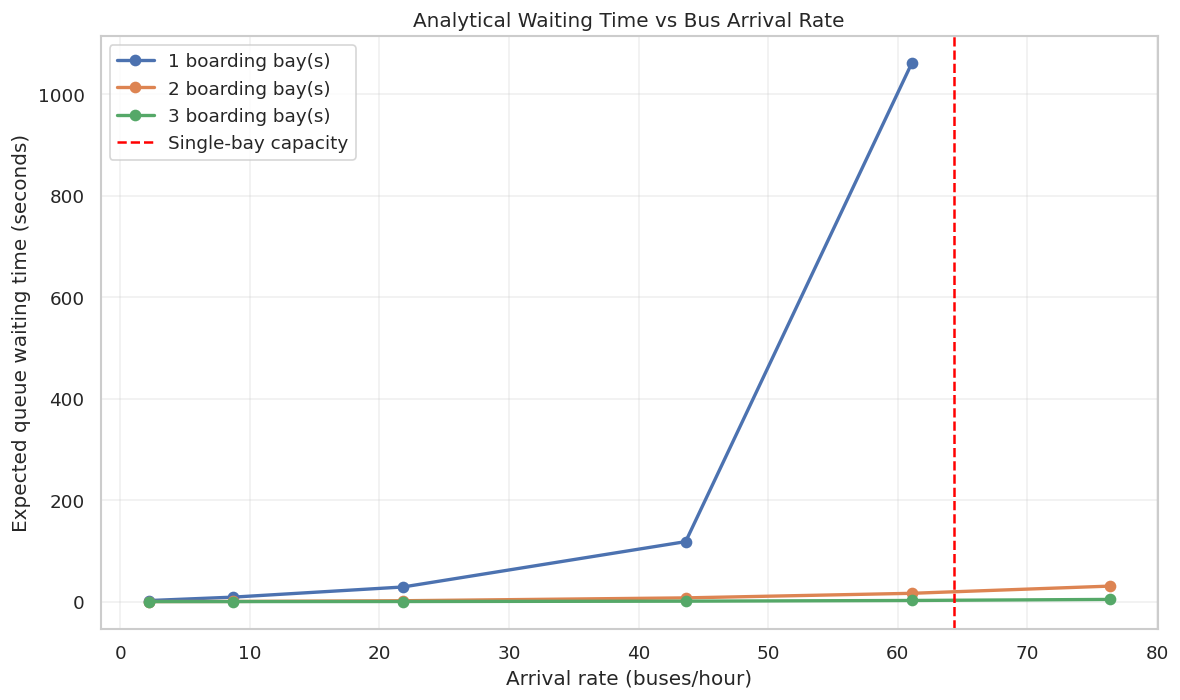

In [32]:
# Analytical waiting-time comparison

plt.figure(figsize=(10, 6))

for bays in BAY_CONFIGURATIONS:

    subset = analytical_df[
        (analytical_df["Bays"] == bays)
        & (analytical_df["stable"])
    ].sort_values("Arrival_rate")

    plt.plot(
        subset["Arrival_rate"],
        subset["Wq_seconds"],
        marker="o",
        linewidth=2,
        label=f"{bays} boarding bay(s)"
    )

plt.axvline(
    MU_BASE,
    color="red",
    linestyle="--",
    label="Single-bay capacity"
)

plt.title("Analytical Waiting Time vs Bus Arrival Rate")

plt.xlabel("Arrival rate (buses/hour)")
plt.ylabel("Expected queue waiting time (seconds)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_analytical_waiting_times.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# High-demand simulation experiment

high_demand_results = []

for bays in BAY_CONFIGURATIONS:

    metrics = simulate_bus_halt_metrics(
        arrival_rate=LAMBDA_BASE * 28,
        service_rate=MU_BASE,
        bays=bays,
        simulation_hours=1000,
        warmup_hours=100,
        seed=42
    )

    high_demand_results.append(metrics)

high_demand_df = pd.DataFrame(
    high_demand_results
)

print("HIGH-DEMAND SIMULATION RESULTS")
print("=" * 75)

print(
    high_demand_df[
        [
            "bays",
            "buses_recorded",
            "mean_wait_seconds",
            "mean_queue_length",
            "utilisation",
            "p95_wait_seconds"
        ]
    ].round(4).to_string(index=False)
)

HIGH-DEMAND SIMULATION RESULTS
 bays  buses_recorded  mean_wait_seconds  mean_queue_length  utilisation  p95_wait_seconds
    1           55032           949.4073            16.1327       0.9504         2870.2770
    2           55032            16.4330             0.2791       0.4751           97.9374
    3           55032             2.2735             0.0386       0.3168           13.5278


In [37]:
# Initial analytical vs simulation comparison

comparison_rows = []

for _, row in high_demand_df.iterrows():

    bays = int(row["bays"])

    theory = mmc_analytical(
        LAMBDA_BASE * 28,
        MU_BASE,
        bays
    )

    theoretical_wait = theory["Wq_seconds"]

    simulated_wait = row["mean_wait_seconds"]

    absolute_error = abs(
        simulated_wait - theoretical_wait
    )

    percentage_error = (
        absolute_error / theoretical_wait
    ) * 100

    comparison_rows.append({
        "Bays": bays,
        "Analytical_wait": theoretical_wait,
        "Simulated_wait": simulated_wait,
        "Absolute_error": absolute_error,
        "Percentage_error": percentage_error,
        "Analytical_utilisation": theory["rho"],
        "Simulated_utilisation": row["utilisation"]
    })

initial_comparison_df = pd.DataFrame(
    comparison_rows
)

print("INITIAL ANALYTICAL VS SIMULATION COMPARISON")
print("=" * 80)

print(
    initial_comparison_df
    .round(4)
    .to_string(index=False)
)

INITIAL ANALYTICAL VS SIMULATION COMPARISON
 Bays  Analytical_wait  Simulated_wait  Absolute_error  Percentage_error  Analytical_utilisation  Simulated_utilisation
    1        1060.9867        949.4073        111.5793           10.5166                  0.9499                 0.9504
    2          16.3071         16.4330          0.1259            0.7722                  0.4749                 0.4751
    3           2.1870          2.2735          0.0865            3.9530                  0.3166                 0.3168


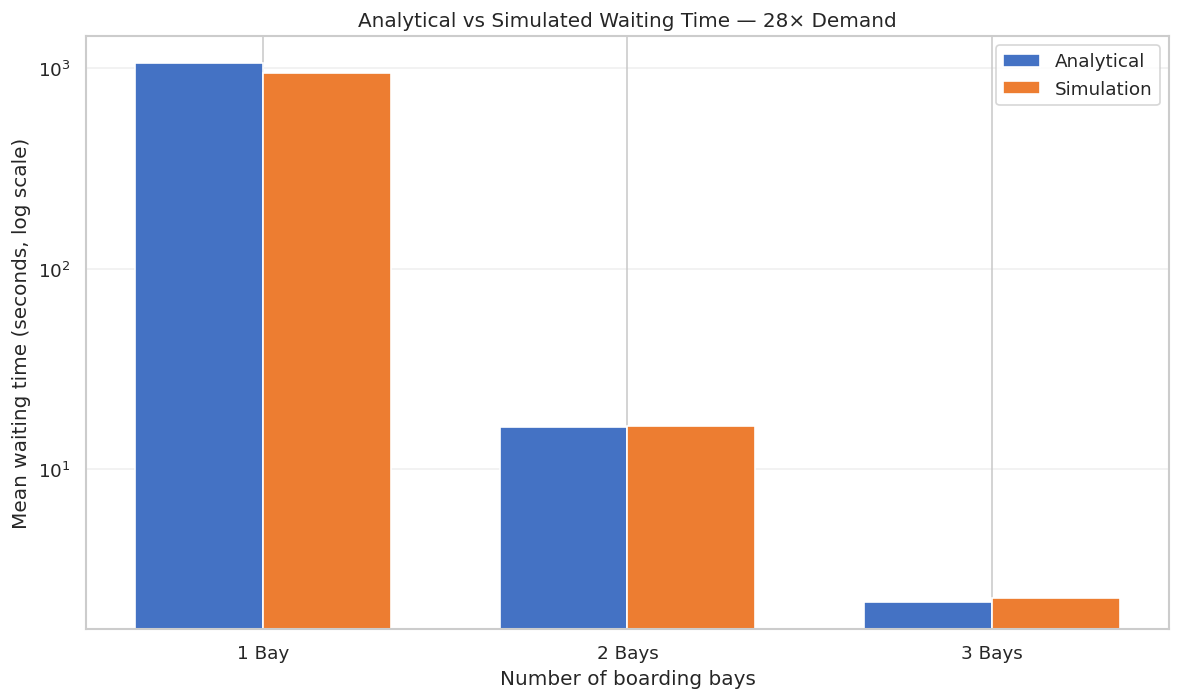

In [38]:
# Analytical vs simulation comparison graph

x = np.arange(len(initial_comparison_df))

width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    initial_comparison_df["Analytical_wait"],
    width,
    label="Analytical",
    color="#4472C4"
)

plt.bar(
    x + width / 2,
    initial_comparison_df["Simulated_wait"],
    width,
    label="Simulation",
    color="#ED7D31"
)

plt.xticks(
    x,
    ["1 Bay", "2 Bays", "3 Bays"]
)

plt.yscale("log")

plt.xlabel("Number of boarding bays")

plt.ylabel("Mean waiting time (seconds, log scale)")

plt.title(
    "Analytical vs Simulated Waiting Time — 28× Demand"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_initial_simulation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
# Experimental configuration

N_REPLICATIONS = 30

EXPERIMENT_HOURS = 1000
WARMUP_HOURS = 100

MASTER_SEED = 2026

seed_sequence = np.random.SeedSequence(
    MASTER_SEED
)

REPLICATION_SEEDS = [
    int(s.generate_state(1)[0])
    for s in seed_sequence.spawn(N_REPLICATIONS)
]

print("EXPERIMENTAL CONFIGURATION")
print("=" * 55)

print("Replications:", N_REPLICATIONS)
print("Simulation hours:", EXPERIMENT_HOURS)
print("Warm-up hours:", WARMUP_HOURS)
print("Master seed:", MASTER_SEED)

print("\nFirst five replication seeds:")
print(REPLICATION_SEEDS[:5])

EXPERIMENTAL CONFIGURATION
Replications: 30
Simulation hours: 1000
Warm-up hours: 100
Master seed: 2026

First five replication seeds:
[479243620, 454024514, 1818751028, 2288458700, 2115331525]


In [40]:
def confidence_interval(values, confidence=0.95):

    values = np.asarray(values, dtype=float)

    n = len(values)

    mean = np.mean(values)

    if n < 2:
        return mean, np.nan, np.nan

    standard_error = stats.sem(values)

    critical_value = stats.t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    margin = critical_value * standard_error

    return (
        mean,
        mean - margin,
        mean + margin
    )


# Test the function
test_values = [10, 12, 11, 13, 14]

mean, lower, upper = confidence_interval(
    test_values
)

assert lower <= mean <= upper

print("Confidence interval function: PASSED")

print("Test mean:", round(mean, 4))
print("Lower bound:", round(lower, 4))
print("Upper bound:", round(upper, 4))

Confidence interval function: PASSED
Test mean: 12.0
Lower bound: 10.0368
Upper bound: 13.9632


In [41]:
# Warm-up sensitivity experiment

warmup_results = []

WARMUP_OPTIONS = [0, 50, 100, 200]

for warmup in WARMUP_OPTIONS:

    waits = []

    for seed in REPLICATION_SEEDS[:10]:

        metrics = simulate_bus_halt_metrics(
            arrival_rate=LAMBDA_BASE * 28,
            service_rate=MU_BASE,
            bays=1,
            simulation_hours=1000 + warmup,
            warmup_hours=warmup,
            seed=seed
        )

        waits.append(
            metrics["mean_wait_seconds"]
        )

    mean, lower, upper = confidence_interval(
        waits
    )

    warmup_results.append({
        "Warmup_hours": warmup,
        "Mean_wait_seconds": mean,
        "CI_lower": lower,
        "CI_upper": upper
    })

    print("Completed warm-up:", warmup)


warmup_df = pd.DataFrame(warmup_results)

print("\nWARM-UP SENSITIVITY RESULTS")
print("=" * 65)

print(
    warmup_df.round(4).to_string(index=False)
)

Completed warm-up: 0
Completed warm-up: 50
Completed warm-up: 100
Completed warm-up: 200

WARM-UP SENSITIVITY RESULTS
 Warmup_hours  Mean_wait_seconds  CI_lower  CI_upper
            0          1008.5079  924.7665 1092.2493
           50          1039.9541  951.3652 1128.5430
          100          1038.8445  958.9416 1118.7475
          200          1017.5463  917.2327 1117.8600


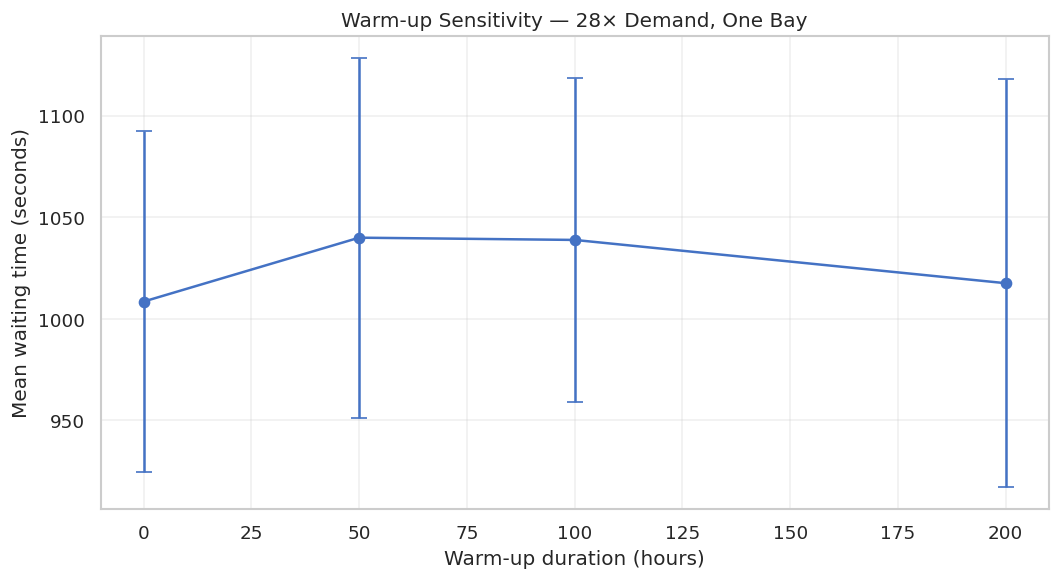

In [42]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    warmup_df["Warmup_hours"],
    warmup_df["Mean_wait_seconds"],
    yerr=[
        warmup_df["Mean_wait_seconds"]
        - warmup_df["CI_lower"],

        warmup_df["CI_upper"]
        - warmup_df["Mean_wait_seconds"]
    ],
    fmt="o-",
    capsize=5,
    color="#4472C4"
)

plt.xlabel("Warm-up duration (hours)")

plt.ylabel("Mean waiting time (seconds)")

plt.title(
    "Warm-up Sensitivity — 28× Demand, One Bay"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "06_warmup_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation of warm-up sensitivity

The warm-up sensitivity experiment evaluated initialisation periods of 0, 50, 100 and 200 hours under the high-demand single-bay scenario.

The estimated mean waiting times ranged from 1008.51 to 1039.95 seconds, with overlapping 95% confidence intervals.

No clear systematic change was observed as the warm-up duration increased. Therefore, a 100-hour warm-up was retained as a reasonable experimental choice to reduce initialisation bias.

However, overlapping confidence intervals do not conclusively establish that all initialisation bias has been eliminated.

In [43]:
# Main steady-state simulation experiments

experiment_results = []

start_time = time.perf_counter()

for multiplier in DEMAND_MULTIPLIERS:

    arrival_rate = LAMBDA_BASE * multiplier

    for bays in BAY_CONFIGURATIONS:

        rho = arrival_rate / (bays * MU_BASE)

        # Exclude unstable steady-state scenarios
        if rho >= 1:

            print(
                f"Skipped unstable scenario: "
                f"{multiplier}x, {bays} bay(s)"
            )

            continue

        for replication, seed in enumerate(
            REPLICATION_SEEDS,
            start=1
        ):

            metrics = simulate_bus_halt_metrics(
                arrival_rate=arrival_rate,
                service_rate=MU_BASE,
                bays=bays,
                simulation_hours=EXPERIMENT_HOURS,
                warmup_hours=WARMUP_HOURS,
                seed=seed,
                service_distribution="exponential"
            )

            metrics["demand_multiplier"] = multiplier

            metrics["replication"] = replication

            experiment_results.append(metrics)

        print(
            f"Completed: {multiplier}x demand, "
            f"{bays} bay(s)"
        )


experiment_df = pd.DataFrame(
    experiment_results
)

elapsed_time = time.perf_counter() - start_time

print("\nEXPERIMENT SUMMARY")
print("=" * 55)

print("Completed runs:", len(experiment_df))

print(
    "Execution time (seconds):",
    round(elapsed_time, 2)
)

print(
    experiment_df.head()
    .round(4)
    .to_string(index=False)
)

Completed: 1x demand, 1 bay(s)
Completed: 1x demand, 2 bay(s)
Completed: 1x demand, 3 bay(s)
Completed: 4x demand, 1 bay(s)
Completed: 4x demand, 2 bay(s)
Completed: 4x demand, 3 bay(s)
Completed: 10x demand, 1 bay(s)
Completed: 10x demand, 2 bay(s)
Completed: 10x demand, 3 bay(s)
Completed: 20x demand, 1 bay(s)
Completed: 20x demand, 2 bay(s)
Completed: 20x demand, 3 bay(s)
Completed: 28x demand, 1 bay(s)
Completed: 28x demand, 2 bay(s)
Completed: 28x demand, 3 bay(s)
Skipped unstable scenario: 35x, 1 bay(s)
Completed: 35x demand, 2 bay(s)
Completed: 35x demand, 3 bay(s)

EXPERIMENT SUMMARY
Completed runs: 510
Execution time (seconds): 435.76
 arrival_rate  service_rate  bays       seed distribution  simulation_hours  warmup_hours  buses_recorded  observed_arrival_rate  mean_wait_seconds  mean_service_seconds  mean_system_seconds  p95_wait_seconds  probability_wait  mean_queue_length  utilisation  max_queue_length  queue_at_end  busy_at_end  theoretical_stable  demand_multiplier  repl

In [44]:
summary_rows = []

for (multiplier, bays), group in experiment_df.groupby(
    ["demand_multiplier", "bays"]
):

    wait_mean, wait_lower, wait_upper = (
        confidence_interval(
            group["mean_wait_seconds"]
        )
    )

    queue_mean, queue_lower, queue_upper = (
        confidence_interval(
            group["mean_queue_length"]
        )
    )

    util_mean, util_lower, util_upper = (
        confidence_interval(
            group["utilisation"]
        )
    )

    summary_rows.append({

        "Demand_multiplier": multiplier,
        "Bays": bays,

        "Replications": len(group),

        "Mean_wait_seconds": wait_mean,
        "Wait_CI_lower": wait_lower,
        "Wait_CI_upper": wait_upper,

        "Mean_queue_length": queue_mean,
        "Queue_CI_lower": queue_lower,
        "Queue_CI_upper": queue_upper,

        "Utilisation": util_mean,
        "Util_CI_lower": util_lower,
        "Util_CI_upper": util_upper,

        "Probability_wait":
            group["probability_wait"].mean(),

        "Mean_replication_p95_wait":
            group["p95_wait_seconds"].mean()
    })


experiment_summary_df = pd.DataFrame(
    summary_rows
)

print("STEADY-STATE EXPERIMENT SUMMARY")
print("=" * 90)

print(
    experiment_summary_df[
        [
            "Demand_multiplier",
            "Bays",
            "Replications",
            "Mean_wait_seconds",
            "Wait_CI_lower",
            "Wait_CI_upper",
            "Mean_queue_length",
            "Utilisation"
        ]
    ].round(4).to_string(index=False)
)

STEADY-STATE EXPERIMENT SUMMARY
 Demand_multiplier  Bays  Replications  Mean_wait_seconds  Wait_CI_lower  Wait_CI_upper  Mean_queue_length  Utilisation
                 1     1            30             1.9466         1.8431         2.0501             0.0012       0.0339
                 1     2            30             0.0146         0.0065         0.0227             0.0000       0.0169
                 1     3            30             0.0000         0.0000         0.0000             0.0000       0.0113
                 4     1            30             8.6919         8.4797         8.9041             0.0210       0.1353
                 4     2            30             0.2520         0.2313         0.2728             0.0006       0.0676
                 4     3            30             0.0088         0.0060         0.0116             0.0000       0.0451
                10     1            30            28.5253        28.1157        28.9349             0.1728       0.3390
        

In [45]:
verification_rows = []

for _, row in experiment_summary_df.iterrows():

    multiplier = row["Demand_multiplier"]

    bays = int(row["Bays"])

    theory = mmc_analytical(
        LAMBDA_BASE * multiplier,
        MU_BASE,
        bays
    )

    theoretical_wait = theory["Wq_seconds"]

    simulated_wait = row["Mean_wait_seconds"]

    lower = row["Wait_CI_lower"]
    upper = row["Wait_CI_upper"]

    absolute_error = abs(
        simulated_wait - theoretical_wait
    )

    percentage_error = (
        absolute_error / theoretical_wait * 100
        if theoretical_wait > 0
        else np.nan
    )

    verification_rows.append({

        "Demand_multiplier": multiplier,
        "Bays": bays,

        "Analytical_wait": theoretical_wait,
        "Simulated_wait": simulated_wait,

        "CI_lower": lower,
        "CI_upper": upper,

        "Absolute_error": absolute_error,
        "Percentage_error": percentage_error,

        "Theory_inside_CI":
            lower <= theoretical_wait <= upper
    })


verification_df = pd.DataFrame(
    verification_rows
)

print("STATISTICAL MODEL VERIFICATION")
print("=" * 95)

print(
    verification_df.round(4)
    .to_string(index=False)
)

inside_count = verification_df[
    "Theory_inside_CI"
].sum()

print(
    f"\nAnalytical predictions inside 95% CIs: "
    f"{inside_count}/{len(verification_df)}"
)

STATISTICAL MODEL VERIFICATION
 Demand_multiplier  Bays  Analytical_wait  Simulated_wait  CI_lower  CI_upper  Absolute_error  Percentage_error  Theory_inside_CI
               1.0     1           1.9660          1.9466    1.8431    2.0501          0.0194            0.9863              True
               1.0     2           0.0161          0.0146    0.0065    0.0227          0.0015            9.4841              True
               1.0     3           0.0001          0.0000    0.0000    0.0000          0.0001          100.0000             False
               4.0     1           8.7900          8.6919    8.4797    8.9041          0.0981            1.1163              True
               4.0     2           0.2589          0.2520    0.2313    0.2728          0.0069            2.6577              True
               4.0     3           0.0074          0.0088    0.0060    0.0116          0.0014           18.2554              True
              10.0     1          28.7444         28.5253  

#### Interpretation of statistical model verification

Analytical M/M/c mean waits fell within 14 of 17 pointwise 95% simulation confidence intervals, based on 30 replications per scenario. A 95% interval targets coverage over repeated experiments under its statistical assumptions. The 17 comparisons are not a simultaneous 95% test, and scenarios share replication seeds, so this count is descriptive.

At baseline with three bays, a bus must find all three bays busy to wait. At the calibrated load, Erlang C gives a wait probability of about 6.36 per million arrivals, or about 0.37 expected waits across the 58,823 measured arrivals in the saved replications. The runs recorded zero waiting events and all replication means were zero. The resulting zero-width interval misses the small positive analytical mean (about 0.0001 seconds). It reflects limited information about rare waits.

The other misses occur at 35× demand. For two bays, the analytical mean is 30.4723 seconds and the interval starts at 30.5257 seconds. For three bays, the corresponding values are 4.2521 and 4.2527 seconds. Point estimates differ from theory by about 0.32 and 0.045 seconds, respectively. Finite-run variability and residual transient bias are possible contributors. These comparisons do not establish a cause for either miss.

At 28× demand with one bay the analytical and simulated means are 1060.9867 and 1060.8490 seconds, a difference of about 0.013%. Overall, the results support the implementation's agreement with the analytical model across a range of loads. Real-world validation would require observed queue waiting times.

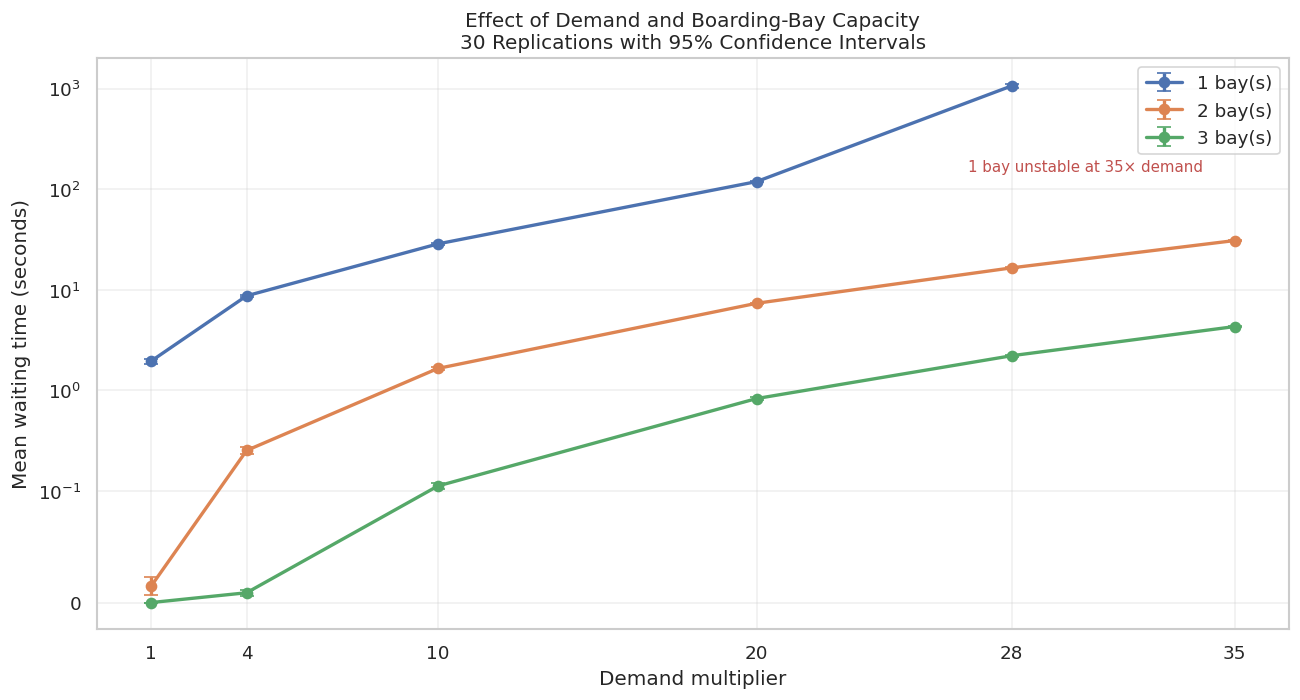

In [54]:
plt.figure(figsize=(11, 6))

for bays in BAY_CONFIGURATIONS:

    subset = experiment_summary_df[
        experiment_summary_df["Bays"] == bays
    ].sort_values("Demand_multiplier")

    plt.errorbar(
        subset["Demand_multiplier"],
        subset["Mean_wait_seconds"],

        yerr=[
            subset["Mean_wait_seconds"]
            - subset["Wait_CI_lower"],

            subset["Wait_CI_upper"]
            - subset["Mean_wait_seconds"]
        ],

        marker="o",
        capsize=4,
        linewidth=2,

        label=f"{bays} bay(s)"
    )

plt.yscale(
    "symlog",
    linthresh=0.1
)

plt.xlabel("Demand multiplier")

plt.ylabel("Mean waiting time (seconds)")

plt.title(
    "Effect of Demand and Boarding-Bay Capacity\n"
    "30 Replications with 95% Confidence Intervals"
)

plt.xticks(DEMAND_MULTIPLIERS)

plt.legend()

plt.grid(alpha=0.3)

plt.annotate(
    "1 bay unstable at 35× demand",
    xy=(35, 1000),
    xytext=(34, 150),
    ha="right",
    fontsize=9,
    color="#C0504D"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "07_demand_capacity_experiment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Effect of demand and boarding-bay capacity

The experimental results demonstrate a nonlinear relationship between bus arrival demand and mean queue waiting time.

At the observed baseline demand, a single boarding bay produced a mean waiting time of only 1.95 seconds, with approximately 3.39% utilisation.

At 28 times baseline demand, the single-bay configuration reached approximately 95.12% utilisation, resulting in a mean waiting time of 1060.85 seconds.

Increasing capacity to two bays reduced the mean waiting time to 16.48 seconds, representing a reduction of approximately 98.45%. A three-bay configuration further reduced waiting time to 2.20 seconds.

At 35 times baseline demand, the single-bay configuration became theoretically unstable and was excluded from steady-state experiments.

These findings demonstrate the importance of matching boarding-bay capacity to arrival demand. However, the increased demand scenarios represent hypothetical sensitivity experiments rather than directly observed traffic conditions in Colombo.

In [55]:
unstable_results = []

HORIZONS = [2, 4, 8, 12, 24]

for hours in HORIZONS:

    for seed in REPLICATION_SEEDS:

        metrics = simulate_bus_halt_metrics(
            arrival_rate=LAMBDA_BASE * 35,
            service_rate=MU_BASE,
            bays=1,
            simulation_hours=hours,
            warmup_hours=0,
            seed=seed
        )

        unstable_results.append({

            "Hours": hours,

            "Queue_at_end":
                metrics["queue_at_end"],

            "Mean_wait_seconds":
                metrics["mean_wait_seconds"],

            "Utilisation":
                metrics["utilisation"]
        })


unstable_df = pd.DataFrame(
    unstable_results
)

unstable_summary_rows = []

for hours, group in unstable_df.groupby("Hours"):

    mean, lower, upper = confidence_interval(
        group["Queue_at_end"]
    )

    unstable_summary_rows.append({

        "Hours": hours,
        "Mean_end_queue": mean,
        "CI_lower": lower,
        "CI_upper": upper,

        "Mean_wait_seconds":
            group["Mean_wait_seconds"].mean()
    })


unstable_summary_df = pd.DataFrame(
    unstable_summary_rows
)

print("UNSTABLE SYSTEM ANALYSIS")
print("=" * 70)

print(
    unstable_summary_df.round(4)
    .to_string(index=False)
)

UNSTABLE SYSTEM ANALYSIS
 Hours  Mean_end_queue  CI_lower  CI_upper  Mean_wait_seconds
     2         33.3667   28.3144   38.4189          1020.4267
     4         60.8000   53.7885   67.8115          1851.9780
     8        106.1333   92.8984  119.3682          3219.8804
    12        155.5667  140.5663  170.5671          4565.3783
    24        303.6000  287.0054  320.1946          8710.9996


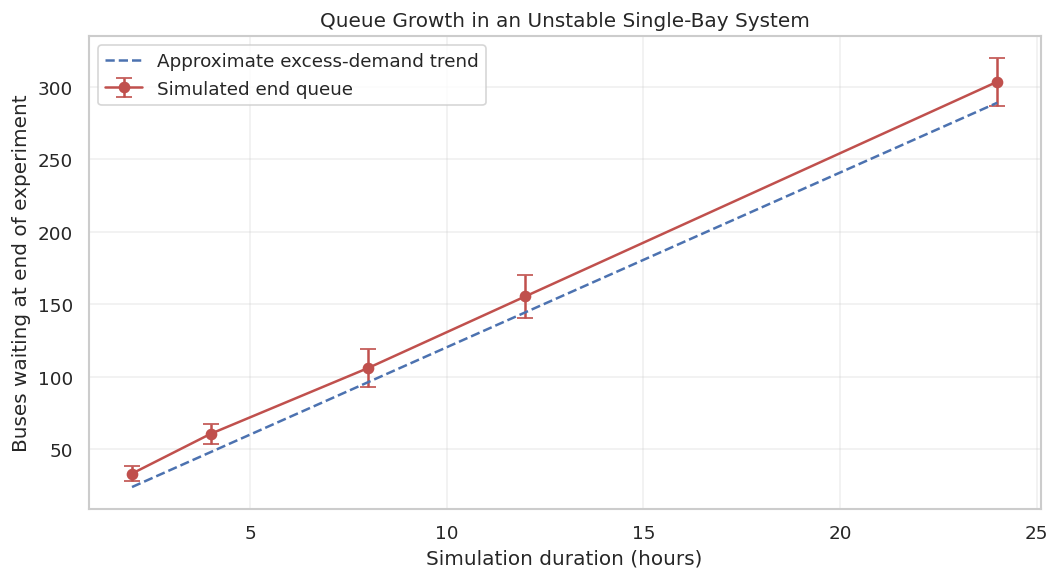

In [56]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    unstable_summary_df["Hours"],
    unstable_summary_df["Mean_end_queue"],

    yerr=[
        unstable_summary_df["Mean_end_queue"]
        - unstable_summary_df["CI_lower"],

        unstable_summary_df["CI_upper"]
        - unstable_summary_df["Mean_end_queue"]
    ],

    marker="o",
    capsize=5,
    color="#C0504D",

    label="Simulated end queue"
)

hours = np.array(HORIZONS)

plt.plot(
    hours,
    (LAMBDA_BASE * 35 - MU_BASE) * hours,
    "--",
    label="Approximate excess-demand trend"
)

plt.xlabel("Simulation duration (hours)")

plt.ylabel("Buses waiting at end of experiment")

plt.title(
    "Queue Growth in an Unstable Single-Bay System"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "08_unstable_queue_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation of unstable system behaviour

At 35 times baseline demand, the single-bay configuration has an arrival rate of approximately 76.35 buses per hour and a service rate of 64.30 buses per hour, resulting in an offered load of about 118.73% of one bay's capacity. The fraction of time a bay is busy is bounded by 100%.

Since the arrival rate exceeds the available service capacity, the system cannot achieve a stable steady state.

The simulated mean end-of-experiment queue increased from 33.37 buses after two hours to 303.60 buses after 24 hours.

The approximate theoretical excess-demand growth rate is 12.05 buses per hour. The simulated results follow a similar increasing trend, with differences attributable to stochastic and transient system behaviour.

These findings demonstrate that insufficient boarding-bay capacity can cause sustained queue accumulation under hypothetical high-demand conditions.

### 5.2 General service-time extension (M/G/c)

The exponential service-time assumption is relaxed using a lognormal service-time distribution.

The fitted lognormal distribution achieved a lower AIC and BIC than the exponential and gamma alternatives, although the gamma distribution achieved a lower KS statistic.

A mean-matched lognormal distribution is used to isolate the effect of service-time distribution shape and variability while maintaining the same average service capacity.

The resulting M/G/c simulation is compared against the original M/M/c model under identical arrival rates and boarding-bay configurations.

The GPS-derived dwell durations are treated as service-time proxies rather than directly measured boarding-bay service times.

In [57]:
lognormal_results = []

EXTENSION_MULTIPLIERS = [10, 20, 28, 35]

for multiplier in EXTENSION_MULTIPLIERS:

    for bays in BAY_CONFIGURATIONS:

        arrival_rate = LAMBDA_BASE * multiplier

        if arrival_rate >= bays * MU_BASE:
            continue

        for replication, seed in enumerate(
            REPLICATION_SEEDS,
            start=1
        ):

            metrics = simulate_bus_halt_metrics(
                arrival_rate=arrival_rate,
                service_rate=MU_BASE,
                bays=bays,
                simulation_hours=EXPERIMENT_HOURS,
                warmup_hours=WARMUP_HOURS,
                seed=seed,
                service_distribution="lognormal",
                lognormal_sigma=0.7759553844290873
            )

            metrics["demand_multiplier"] = multiplier

            metrics["replication"] = replication

            lognormal_results.append(metrics)

        print(
            f"Completed lognormal: "
            f"{multiplier}x, {bays} bay(s)"
        )


lognormal_df = pd.DataFrame(
    lognormal_results
)

print("\nLOGNORMAL EXPERIMENT SUMMARY")
print("=" * 55)

print("Completed runs:", len(lognormal_df))

print(
    lognormal_df.groupby(
        ["demand_multiplier", "bays"]
    )["mean_wait_seconds"]
    .mean()
    .round(4)
    .to_string()
)

Completed lognormal: 10x, 1 bay(s)
Completed lognormal: 10x, 2 bay(s)
Completed lognormal: 10x, 3 bay(s)
Completed lognormal: 20x, 1 bay(s)
Completed lognormal: 20x, 2 bay(s)
Completed lognormal: 20x, 3 bay(s)
Completed lognormal: 28x, 1 bay(s)
Completed lognormal: 28x, 2 bay(s)
Completed lognormal: 28x, 3 bay(s)
Completed lognormal: 35x, 2 bay(s)
Completed lognormal: 35x, 3 bay(s)

LOGNORMAL EXPERIMENT SUMMARY
Completed runs: 330
demand_multiplier  bays
10                 1         26.1415
                   2          1.4450
                   3          0.0928
20                 1        108.7412
                   2          6.4557
                   3          0.7167
28                 1       1025.4316
                   2         14.6693
                   3          1.9322
35                 2         27.5903
                   3          3.7659


In [58]:
# Paired comparison using matching replication seeds

paired_df = experiment_df.merge(
    lognormal_df,

    on=[
        "demand_multiplier",
        "bays",
        "replication",
        "seed"
    ],

    suffixes=("_mmc", "_mgc")
)

paired_df["wait_difference"] = (
    paired_df["mean_wait_seconds_mgc"]
    - paired_df["mean_wait_seconds_mmc"]
)

distribution_rows = []

for (multiplier, bays), group in paired_df.groupby(
    ["demand_multiplier", "bays"]
):

    mmc_mean = group[
        "mean_wait_seconds_mmc"
    ].mean()

    mgc_mean = group[
        "mean_wait_seconds_mgc"
    ].mean()

    diff, lower, upper = confidence_interval(
        group["wait_difference"]
    )

    distribution_rows.append({

        "Demand_multiplier": multiplier,
        "Bays": bays,

        "MMC_wait": mmc_mean,
        "MGC_wait": mgc_mean,

        "Difference": diff,

        "Difference_CI_lower": lower,
        "Difference_CI_upper": upper,

        "Change_percent":
            (mgc_mean - mmc_mean) / mmc_mean * 100
            if mmc_mean > 0
            else np.nan
    })


distribution_comparison_df = pd.DataFrame(
    distribution_rows
)

print("SERVICE DISTRIBUTION COMPARISON")
print("=" * 90)

print(
    distribution_comparison_df
    .round(4)
    .to_string(index=False)
)

SERVICE DISTRIBUTION COMPARISON
 Demand_multiplier  Bays  MMC_wait  MGC_wait  Difference  Difference_CI_lower  Difference_CI_upper  Change_percent
                10     1   28.5253   26.1415     -2.3838              -2.8174              -1.9502         -8.3568
                10     2    1.6473    1.4450     -0.2024              -0.2516              -0.1532        -12.2858
                10     3    0.1117    0.0928     -0.0189              -0.0297              -0.0082        -16.9404
                20     1  118.7446  108.7412    -10.0034             -11.9036              -8.1032         -8.4243
                20     2    7.3237    6.4557     -0.8680              -0.9903              -0.7457        -11.8521
                20     3    0.8269    0.7167     -0.1101              -0.1332              -0.0870        -13.3183
                28     1 1060.8490 1025.4316    -35.4174             -97.0059              26.1712         -3.3386
                28     2   16.4800   14.6693    

In [59]:
# Analytical verification of the M/G/1 extension

SIGMA = 0.7759553844290873

mean_service = 3600 / MU_BASE

second_moment = (
    mean_service**2 * np.exp(SIGMA**2)
)

mg1_rows = []

for multiplier in [10, 20, 28]:

    # Convert arrival rate to buses per second
    arrival_rate_seconds = (
        LAMBDA_BASE * multiplier / 3600
    )

    rho = arrival_rate_seconds * mean_service

    theoretical_wait = (
        arrival_rate_seconds * second_moment
        / (2 * (1 - rho))
    )

    subset = lognormal_df[
        (lognormal_df["demand_multiplier"] == multiplier)
        & (lognormal_df["bays"] == 1)
    ]

    mean, lower, upper = confidence_interval(
        subset["mean_wait_seconds"]
    )

    mg1_rows.append({

        "Demand_multiplier": multiplier,

        "Analytical_wait": theoretical_wait,

        "Simulated_wait": mean,

        "CI_lower": lower,
        "CI_upper": upper,

        "Theory_inside_CI":
            lower <= theoretical_wait <= upper
    })


mg1_verification_df = pd.DataFrame(
    mg1_rows
)

print("M/G/1 ANALYTICAL VERIFICATION")
print("=" * 80)

print(
    mg1_verification_df
    .round(4)
    .to_string(index=False)
)

M/G/1 ANALYTICAL VERIFICATION
 Demand_multiplier  Analytical_wait  Simulated_wait  CI_lower  CI_upper  Theory_inside_CI
                10          26.2431         26.1415   25.7999   26.4832              True
                20         107.8657        108.7412  106.7612  110.7212              True
                28         968.6605       1025.4316  963.8550 1087.0082              True


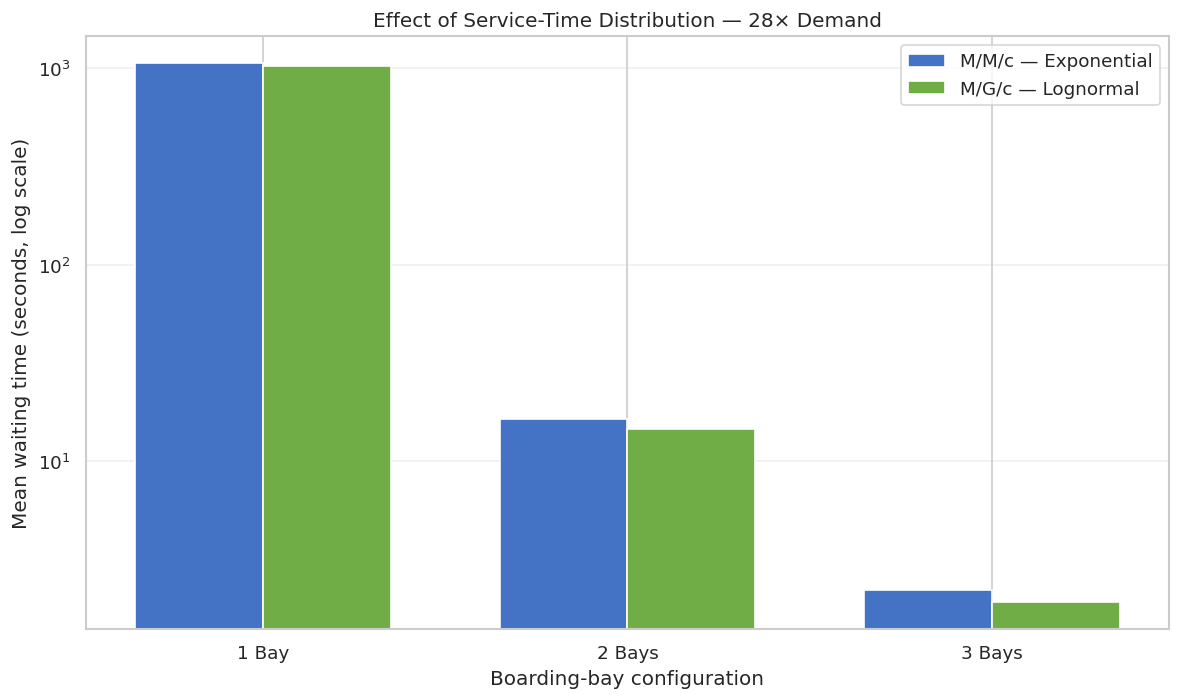

In [60]:
subset = distribution_comparison_df[
    distribution_comparison_df[
        "Demand_multiplier"
    ] == 28
].sort_values("Bays")

x = np.arange(len(subset))

width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    subset["MMC_wait"],
    width,
    label="M/M/c — Exponential",
    color="#4472C4"
)

plt.bar(
    x + width / 2,
    subset["MGC_wait"],
    width,
    label="M/G/c — Lognormal",
    color="#70AD47"
)

plt.xticks(
    x,
    ["1 Bay", "2 Bays", "3 Bays"]
)

plt.yscale("log")

plt.ylabel("Mean waiting time (seconds, log scale)")

plt.xlabel("Boarding-bay configuration")

plt.title(
    "Effect of Service-Time Distribution — 28× Demand"
)

plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "09_distribution_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Effect of service-time distribution

The M/G/c extension investigated the sensitivity of queue performance to the assumed service-time distribution.

The lognormal distribution was selected based on its lower AIC and BIC values when fitted to the observed positive dwell-time data.

A total of 330 additional simulations were conducted across 11 stable demand-capacity scenarios.

The lognormal model produced lower estimated mean waiting times in all tested scenarios, with reductions ranging from approximately 3.34% to 16.94%.

However, the confidence interval for the difference in the 28-times-demand single-bay scenario included zero, indicating that the observed reduction was not statistically conclusive.

The results demonstrate that service-time distribution assumptions influence estimated queue performance. Nevertheless, both models support the same general conclusion that increasing boarding-bay capacity substantially reduces congestion under high-demand conditions.

The lognormal extension improves the empirical grounding of the service-time assumptions but does not constitute direct validation against real-world queue waiting times.

#### M/G/1 analytical verification

The Pollaczek–Khinchine formula [2] was used to verify the single-bay simulation with lognormal service times. With $m = 3600/\mu$ in seconds and $\sigma = 0.7759553844290873$, the code sets the mean of $\log S$ to $\log m - \sigma^2/2$. Then $E[S] = m$ and $E[S^2] = m^2\exp(\sigma^2)$. The coefficient of variation is $\sqrt{\exp(\sigma^2)-1}$, approximately 0.91 versus 1 for exponential service. With arrivals converted to buses per second, $W_q = \lambda E[S^2]/(2(1-\rho))$ is in seconds.

Analytical predictions were compared with simulated mean waiting times at demand multipliers of 10, 20 and 28.

In all three scenarios, the analytical prediction fell within the corresponding simulation-based 95% confidence interval.

These results provide additional evidence that the discrete-event simulation correctly represents the theoretical behaviour of an M/G/1 queue under the tested assumptions.

The verification applies to the single-bay model and does not independently establish the correctness of every multi-bay configuration or validate the model against observed real-world queue waiting times.

## 6. Discussion and limitations

**Baseline demand.** The GPS-derived inputs give 2.18 arrivals per hour and a mean positive dwell time of about 56 seconds. Under those inputs, the simulated single bay is busy about 3.39% of the time and the mean queue wait is about 1.95 seconds. The baseline results provide little queueing justification for adding a bay at that load. Very small waits with three bays are difficult to estimate from a finite sample.

**Demand and capacity.** Mean wait grows sharply as demand approaches capacity. At 28× baseline demand, one bay averages 1060.85 seconds of waiting, versus 16.48 seconds with two bays and 2.20 seconds with three. At 35×, one bay has no finite steady-state mean wait. In the finite-horizon experiment, the mean queue remaining at the cutoff grows from 33.37 buses at two hours to 303.60 at 24 hours. Two and three bays remain stable in that stress scenario. A second bay is therefore the first capacity option to investigate if site measurements show sustained demand near one bay's capacity. Weigh a third bay against measured peak demand, acceptable waits, available space and cost.

**Verification and uncertainty.** The stable scenarios use 30 independent replications each. Their 95% intervals describe simulation sampling uncertainty for fixed inputs, so they do not measure uncertainty about the real halt or account for every source of model error. The M/M/c comparison gives 14 of 17 analytical values inside their intervals, with the rare-event and high-demand exceptions discussed above. The mean-matched lognormal estimates are lower in all 11 paired scenarios, though the interval for the difference includes zero at 28× with one bay. The M/G/1 analytical reference falls inside all three corresponding intervals and applies to the single-bay extension.

**Limits of the evidence.** GPS-derived positive dwell time is a proxy for bay service time. It can reflect passenger activity and other stop delays. It does not directly reveal when a bus began queueing or whether all bays were occupied. The inputs come from one Kandy–Digana stop, and the demand multipliers are hypothetical stress tests. They are not measured Colombo traffic volumes. Analytical verification checks whether the implementation matches the mathematical model. Real-world validation requires independently observed waits, arrivals and bay occupancy at the site of interest.

**Future work.** Record arrival, queue entry, service start and departure times across several peak periods. Use these observations to check whether arrivals cluster, whether bays interfere with each other and whether queues spill back. Compare predictions against held-out days and quantify how input uncertainty affects the bay-count decision.

## 7. References

1. Shiveswarran R, “Bus travel time data,” Kaggle, ver. 2, Apr. 26, 2023. [Online]. Available: https://www.kaggle.com/datasets/shiveswarranr/bus-travel-time-data
2. J. F. Shortle, J. M. Thompson, D. Gross, and C. M. Harris, *Fundamentals of Queueing Theory*, 5th ed. Wiley, 2018, doi: 10.1002/9781119453765.
3. SimPy, “SimPy documentation.” [Online]. Available: https://simpy.readthedocs.io/
4. S. Ratneswaran and U. Thayasivam, “Extracting potential travel time information from raw GPS data and evaluating the performance of public transit - a case study in Kandy, Sri Lanka,” in *Proc. 2023 Int. Conf. Intelligent Communication and Computational Techniques (ICCT)*, 2023, pp. 1–7, doi: 10.1109/ICCT56969.2023.10075789. Processing-method reference supplied by the dataset publisher.

In [61]:
RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

datasets_to_save = {

    "warmup_sensitivity.csv":
        warmup_df,

    "simulation_replications.csv":
        experiment_df,

    "experiment_summary.csv":
        experiment_summary_df,

    "analytical_verification.csv":
        verification_df,

    "unstable_system_analysis.csv":
        unstable_summary_df,

    "lognormal_replications.csv":
        lognormal_df,

    "distribution_comparison.csv":
        distribution_comparison_df,

    "mg1_verification.csv":
        mg1_verification_df
}

for filename, dataframe in datasets_to_save.items():

    dataframe.to_csv(
        RESULTS_DIR / filename,
        index=False
    )

    print("Saved:", filename)

print("\nAll experimental results saved.")

Saved: warmup_sensitivity.csv
Saved: simulation_replications.csv
Saved: experiment_summary.csv
Saved: analytical_verification.csv
Saved: unstable_system_analysis.csv
Saved: lognormal_replications.csv
Saved: distribution_comparison.csv
Saved: mg1_verification.csv

All experimental results saved.


In [ ]:
import shutil

# The archives are available in the Colab Files pane after this cell runs.
shutil.make_archive("experimental_results", "zip", RESULTS_DIR)
shutil.make_archive("experimental_figures", "zip", FIGURE_DIR)
print("Archives saved: experimental_results.zip and experimental_figures.zip")